# 🖨️ Printing Defect Detection — YOLOv5s Baseline (Phase 2)

This notebook trains and evaluates a **YOLOv5s** baseline model on your printing-defect
dataset (2435 images, 15 defect classes, 70:20:10 train/valid/test split, no augmentation
applied yet — only 512×512 resizing).

This is the **baseline** experiment. Later you will repeat the exact same pipeline with
YOLOv8 and YOLO11 (Phase 3), and eventually add augmentation (Phase 7) once you know
which classes need help.

**What this notebook does, step by step:**
1. Set up the Colab environment and install YOLOv5
2. Load and fix `data.yaml`, upload/extract your dataset
3. Inspect the dataset (class balance, sample images) — with a special note on
   `ink_spots_on_paper`, which has far more annotations than the other 14 classes
4. Train YOLOv5s from pretrained (COCO) weights, **with augmentation turned off**
   to match your "baseline, no augmentation" plan
5. Evaluate on the held-out **test** set: Precision, Recall, mAP@0.5, mAP@0.5:0.95, F1
6. Build a **class-wise performance table** for all 15 classes
7. Show the confusion matrix and training/evaluation plots
8. Run predictions on test images and save annotated example images
9. Summarize which defect classes are detected well vs. poorly
10. Save everything (weights + results) so you can reuse it for the report / Phase 3

> 💡 **Tip:** Runtime → Change runtime type → Hardware accelerator → **GPU** (T4 is fine)
> before you start, or training will be extremely slow.


## Step 0 — Configuration

Edit the settings below if needed, then just run every cell in order (Runtime → Run all).


In [1]:
# ------------------------------------------------------------------
# CONFIG — edit these if you need to, otherwise just leave as-is
# ------------------------------------------------------------------
import os

PROJECT_DIR = os.getcwd()  # local Jupyter working directory

# Find Augmented_Dataset in the current directory or any parent directory.
# In the Jupyter file browser screenshot, Augmented_Dataset is at the home/root level.
_search_dir = os.path.abspath(PROJECT_DIR)
DATASET_DIR = None
while True:
    _candidate = os.path.join(_search_dir, "Augmented_Dataset")
    if os.path.isdir(_candidate):
        DATASET_DIR = _candidate
        break
    _parent = os.path.dirname(_search_dir)
    if _parent == _search_dir:
        break
    _search_dir = _parent

if DATASET_DIR is None:
    # Clear expected location for an actionable error if the folder is not found.
    DATASET_DIR = os.path.join(os.path.abspath(os.path.expanduser("~")), "Augmented_Dataset")

# Dataset is already extracted into this folder in the project directory (no zip involved)
# DATASET_DIR is resolved above from the local Jupyter working directory.

# Where all run outputs (weights, plots, predictions) will be written
RUNS_DIR = os.path.join(PROJECT_DIR, "runs")

# Training hyperparameters
IMG_SIZE   = 512      # dataset was already resized to 512x512 by Roboflow
BATCH_SIZE = 16
EPOCHS     = 100
PATIENCE   = 30       # early stopping: stop if no improvement for this many epochs
WEIGHTS    = "yolov5s.pt"   # pretrained COCO weights (small model)
RUN_NAME   = "baseline_yolov5s"

# Use YOLOv5's built-in "no augmentation" hyperparameter file so this run matches
# your plan: "for now no augmentation, only 512x512 resizing". You can switch this
# to hyp.scratch-low.yaml later in Phase 7 once you're ready to test augmentation.
HYP_FILE = "data/hyps/hyp.no-augmentation.yaml"

# Set to True if you want results also copied to your Google Drive
SAVE_TO_DRIVE = False
DRIVE_SAVE_FOLDER = os.path.join(PROJECT_DIR, "drive_backup", "printing_defect_yolov5s_baseline")  # not used unless SAVE_TO_DRIVE=True

print("Config loaded.")


Config loaded.


## Step 1 — Check GPU and set up YOLOv5

We check that a GPU is available, then clone the official `ultralytics/yolov5` repo
and install its requirements.


In [2]:
# Check GPU (will show "not found" on CPU-only / non-NVIDIA machines — that is fine, just informational)
!nvidia-smi || echo "No NVIDIA GPU detected — continuing on CPU"


/bin/bash: line 1: nvidia-smi: command not found
No NVIDIA GPU detected — continuing on CPU


In [3]:
# Download and set up the official YOLOv5 repository without requiring Git.
# This works in Jupyter environments where the `git` executable is not installed.
import os
import sys
import shutil
import zipfile
import tempfile
import urllib.request
import subprocess
from pathlib import Path

YOLOV5_DIR = os.path.join(PROJECT_DIR, "yolov5")
TRAIN_SCRIPT = os.path.join(YOLOV5_DIR, "train.py")


def ensure_yolov5_repo():
    if os.path.isfile(TRAIN_SCRIPT):
        print("Using existing YOLOv5 repository:", YOLOV5_DIR)
        return

    print("YOLOv5 repository is missing or incomplete. Downloading the official source archive...")
    archive_url = "https://codeload.github.com/ultralytics/yolov5/zip/refs/heads/master"

    with tempfile.TemporaryDirectory(prefix="yolov5_setup_") as temp_dir:
        archive_path = os.path.join(temp_dir, "yolov5.zip")
        request = urllib.request.Request(
            archive_url,
            headers={"User-Agent": "Mozilla/5.0"},
        )
        with urllib.request.urlopen(request, timeout=120) as response, open(archive_path, "wb") as archive_file:
            shutil.copyfileobj(response, archive_file)

        extract_dir = os.path.join(temp_dir, "extracted")
        os.makedirs(extract_dir, exist_ok=True)
        with zipfile.ZipFile(archive_path, "r") as archive:
            archive.extractall(extract_dir)

        extracted_repo = os.path.join(extract_dir, "yolov5-master")
        if not os.path.isfile(os.path.join(extracted_repo, "train.py")):
            raise FileNotFoundError("Downloaded YOLOv5 archive does not contain train.py.")

        # Preserve an incomplete existing folder rather than deleting user files.
        if os.path.exists(YOLOV5_DIR):
            backup_dir = YOLOV5_DIR + "_incomplete_backup"
            suffix = 1
            while os.path.exists(backup_dir):
                backup_dir = YOLOV5_DIR + f"_incomplete_backup_{suffix}"
                suffix += 1
            shutil.move(YOLOV5_DIR, backup_dir)
            print("Moved incomplete YOLOv5 folder to:", backup_dir)

        shutil.move(extracted_repo, YOLOV5_DIR)

    if not os.path.isfile(TRAIN_SCRIPT):
        raise FileNotFoundError("YOLOv5 setup finished, but train.py is still missing: " + TRAIN_SCRIPT)
    print("YOLOv5 source ready:", YOLOV5_DIR)


ensure_yolov5_repo()

# Install YOLOv5 dependencies using this notebook's active Python interpreter.
requirements_path = os.path.join(YOLOV5_DIR, "requirements.txt")
if not os.path.isfile(requirements_path):
    raise FileNotFoundError("YOLOv5 requirements.txt not found: " + requirements_path)

subprocess.check_call([sys.executable, "-m", "pip", "install", "-r", requirements_path])
subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "pandas", "matplotlib", "seaborn", "opencv-python-headless"
])

import torch
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No NVIDIA GPU detected — continuing on CPU")


YOLOv5 repository is missing or incomplete. Downloading the official source archive...
YOLOv5 source ready: /home/23CSU030/Major project phase2/code/yolov5
Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.9 kB/s eta 0:00:00a 0:00:03
  Attempting uninstall: ultralytics-platform
    Found existing installation: ultralytics-platform 0.1.50
    Uninstalling ultralytics-platform-0.1.50:
      Successfully uninstalled ultralytics-platform-0.1.50
  Attempting uninstall: ultralytics-thop
    Found existing installation: ultralytics-thop 2.1.6
    Uninstalling ultralytics-thop-2.1.6:
      Successfully uninstalled ultralytics-thop-2.1.6
  Attempting uninstall: ultralytics
    Found existing installation: ultralytics 8.4.158
    Uninstalling ultralytics-8.4.158:
      Successfully uninstalled ultralytics-8.4.158
Defaulting to user installation because normal site-packages is not writeable
PyTorch: 2.14.0+cu130

## Step 2 — Point to your dataset folder

The dataset is already extracted into the `Dataset` folder inside your project
directory (no zip file, no upload/extract step needed).


In [5]:
# Dataset is already extracted into a folder in the project directory (no zip, no unzip needed)
import os

assert os.path.exists(DATASET_DIR), f"Folder not found: {DATASET_DIR}"
print("Using dataset folder:", DATASET_DIR)
print(os.listdir(DATASET_DIR))


Using dataset folder: /home/23CSU030/Major project phase2/Augmented_Dataset
['valid', 'train', 'README.roboflow.txt', 'data.yaml', '.ipynb_checkpoints', 'test', 'data_fixed.yaml']


## Step 3 — Load `data.yaml`

Roboflow's exported `data.yaml` uses paths like `../train/images`, which assumes the
yaml file sits one folder deeper than it actually does. We load it, print its contents,
then write a corrected copy with absolute paths so YOLOv5 can find your images no
matter where the dataset is unzipped.


In [6]:
import yaml, os

original_yaml_path = os.path.join(DATASET_DIR, "data.yaml")

with open(original_yaml_path, "r") as f:
    data_cfg = yaml.safe_load(f)

print("Original data.yaml contents:")
print(yaml.dump(data_cfg, sort_keys=False))

CLASS_NAMES = data_cfg["names"]
NUM_CLASSES = data_cfg["nc"]
print(f"Classes ({NUM_CLASSES}): {CLASS_NAMES}")


Original data.yaml contents:
train: ../train/images
val: ../valid/images
test: ../test/images
nc: 15
names:
- broken_extra_wrong_characters
- colour_difference
- cropped_image
- double_printing
- faded_print
- incorrect_size
- ink_spots_on_paper
- misalignment
- missing_print
- missing_section
- random_black_white_lines
- smudges
- tears_wrinkles_folds
- uneven_ink_density
- wrong_font
roboflow:
  workspace: anisha-boken
  project: final_dataset-ejas2
  version: 4
  license: Private
  url: https://app.roboflow.com/anisha-boken/final_dataset-ejas2/4

Classes (15): ['broken_extra_wrong_characters', 'colour_difference', 'cropped_image', 'double_printing', 'faded_print', 'incorrect_size', 'ink_spots_on_paper', 'misalignment', 'missing_print', 'missing_section', 'random_black_white_lines', 'smudges', 'tears_wrinkles_folds', 'uneven_ink_density', 'wrong_font']


In [7]:
# Write a corrected data.yaml with absolute, unambiguous paths
fixed_cfg = {
    "train": os.path.join(DATASET_DIR, "train", "images"),
    "val":   os.path.join(DATASET_DIR, "valid", "images"),
    "test":  os.path.join(DATASET_DIR, "test", "images"),
    "nc":    NUM_CLASSES,
    "names": CLASS_NAMES,
}

FIXED_YAML_PATH = os.path.join(DATASET_DIR, "data_fixed.yaml")
with open(FIXED_YAML_PATH, "w") as f:
    yaml.dump(fixed_cfg, f, sort_keys=False)

print("Fixed data.yaml written to:", FIXED_YAML_PATH)
print(yaml.dump(fixed_cfg, sort_keys=False))


Fixed data.yaml written to: /home/23CSU030/Major project phase2/Augmented_Dataset/data_fixed.yaml
train: /home/23CSU030/Major project phase2/Augmented_Dataset/train/images
val: /home/23CSU030/Major project phase2/Augmented_Dataset/valid/images
test: /home/23CSU030/Major project phase2/Augmented_Dataset/test/images
nc: 15
names:
- broken_extra_wrong_characters
- colour_difference
- cropped_image
- double_printing
- faded_print
- incorrect_size
- ink_spots_on_paper
- misalignment
- missing_print
- missing_section
- random_black_white_lines
- smudges
- tears_wrinkles_folds
- uneven_ink_density
- wrong_font



## Step 4 — Sanity-check the dataset

Count images/labels per split and confirm the 70:20:10 split, then look at the class
distribution. Watch for `ink_spots_on_paper` — it has noticeably more annotations than
every other class in this dataset, which is a class-imbalance issue worth keeping in
mind when we read the results later.


In [8]:
from glob import glob

splits = ["train", "valid", "test"]
counts = {}
for split in splits:
    img_dir = os.path.join(DATASET_DIR, split, "images")
    lbl_dir = os.path.join(DATASET_DIR, split, "labels")
    n_img = len(glob(os.path.join(img_dir, "*")))
    n_lbl = len(glob(os.path.join(lbl_dir, "*.txt")))
    counts[split] = n_img
    print(f"{split:6s} -> images: {n_img:5d}   label files: {n_lbl:5d}")

total = sum(counts.values())
print(f"\nTotal images: {total}")
for split in splits:
    print(f"  {split}: {counts[split]/total*100:.1f}%")


train  -> images:  1769   label files:  1642
valid  -> images:   487   label files:   487
test   -> images:   243   label files:   243

Total images: 2499
  train: 70.8%
  valid: 19.5%
  test: 9.7%


In [9]:
# Count annotations (bounding boxes) per class, across the whole dataset
import pandas as pd
from collections import Counter

def count_class_instances(splits, class_names):
    counter = Counter()
    per_split_counter = {s: Counter() for s in splits}
    for split in splits:
        lbl_dir = os.path.join(DATASET_DIR, split, "labels")
        for lbl_file in glob(os.path.join(lbl_dir, "*.txt")):
            with open(lbl_file, "r") as f:
                for line in f:
                    line = line.strip()
                    if not line:
                        continue
                    cls_id = int(line.split()[0])
                    counter[cls_id] += 1
                    per_split_counter[split][cls_id] += 1
    return counter, per_split_counter

total_counter, per_split_counter = count_class_instances(splits, CLASS_NAMES)

dist_df = pd.DataFrame({
    "class_id": list(range(NUM_CLASSES)),
    "class_name": CLASS_NAMES,
    "train": [per_split_counter["train"].get(i, 0) for i in range(NUM_CLASSES)],
    "valid": [per_split_counter["valid"].get(i, 0) for i in range(NUM_CLASSES)],
    "test":  [per_split_counter["test"].get(i, 0) for i in range(NUM_CLASSES)],
})
dist_df["total"] = dist_df["train"] + dist_df["valid"] + dist_df["test"]
dist_df = dist_df.sort_values("total", ascending=False).reset_index(drop=True)

dist_df


,class_id,class_name,train,valid,test,total
0,6,ink_spots_on_paper,1050,348,155,1553
1,3,double_printing,430,120,68,618
2,10,random_black_white_lines,332,90,58,480
3,7,misalignment,288,87,46,421
4,11,smudges,274,84,41,399
5,4,faded_print,239,68,31,338
6,9,missing_section,238,65,33,336
7,5,incorrect_size,228,71,34,333
8,1,colour_difference,226,58,27,311
9,12,tears_wrinkles_folds,201,68,34,303


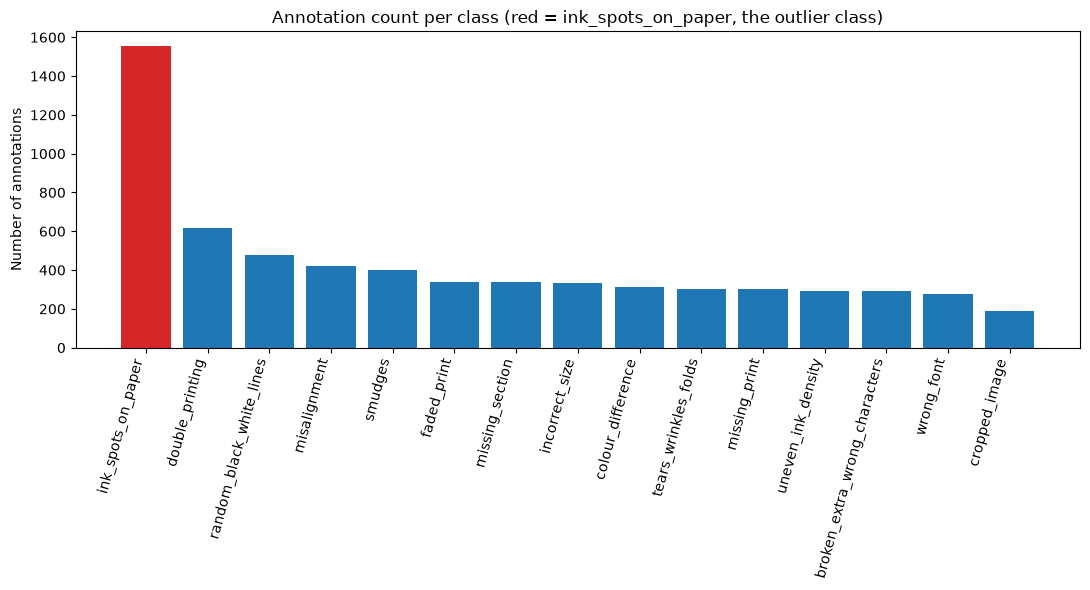

ink_spots_on_paper: 1553 annotations
Average of the other 14 classes: 350 annotations
ink_spots_on_paper has ~4.4x more annotations than the average class.

⚠️  This is a class imbalance. Keep it in mind: the model may learn to detect
   ink_spots_on_paper very well simply because it has seen it so much more often,
   while rarer classes may lag behind. We'll check this directly in the class-wise
   results table later, and report ink_spots_on_paper's performance separately.


In [10]:
# Visualize class distribution — this makes the ink_spots_on_paper imbalance obvious
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))
colors = ["#d62728" if name == "ink_spots_on_paper" else "#1f77b4" for name in dist_df["class_name"]]
plt.bar(dist_df["class_name"], dist_df["total"], color=colors)
plt.xticks(rotation=75, ha="right")
plt.ylabel("Number of annotations")
plt.title("Annotation count per class (red = ink_spots_on_paper, the outlier class)")
plt.tight_layout()
plt.show()

avg_other = dist_df.loc[dist_df["class_name"] != "ink_spots_on_paper", "total"].mean()
ink_count = dist_df.loc[dist_df["class_name"] == "ink_spots_on_paper", "total"].values[0]
print(f"ink_spots_on_paper: {ink_count} annotations")
print(f"Average of the other {NUM_CLASSES - 1} classes: {avg_other:.0f} annotations")
print(f"ink_spots_on_paper has ~{ink_count/avg_other:.1f}x more annotations than the average class.")
print("\n⚠️  This is a class imbalance. Keep it in mind: the model may learn to detect")
print("   ink_spots_on_paper very well simply because it has seen it so much more often,")
print("   while rarer classes may lag behind. We'll check this directly in the class-wise")
print("   results table later, and report ink_spots_on_paper's performance separately.")


## Step 5 — Look at a few sample images with their ground-truth boxes

Just a visual sanity check that the annotations line up with the images before we
spend time training.


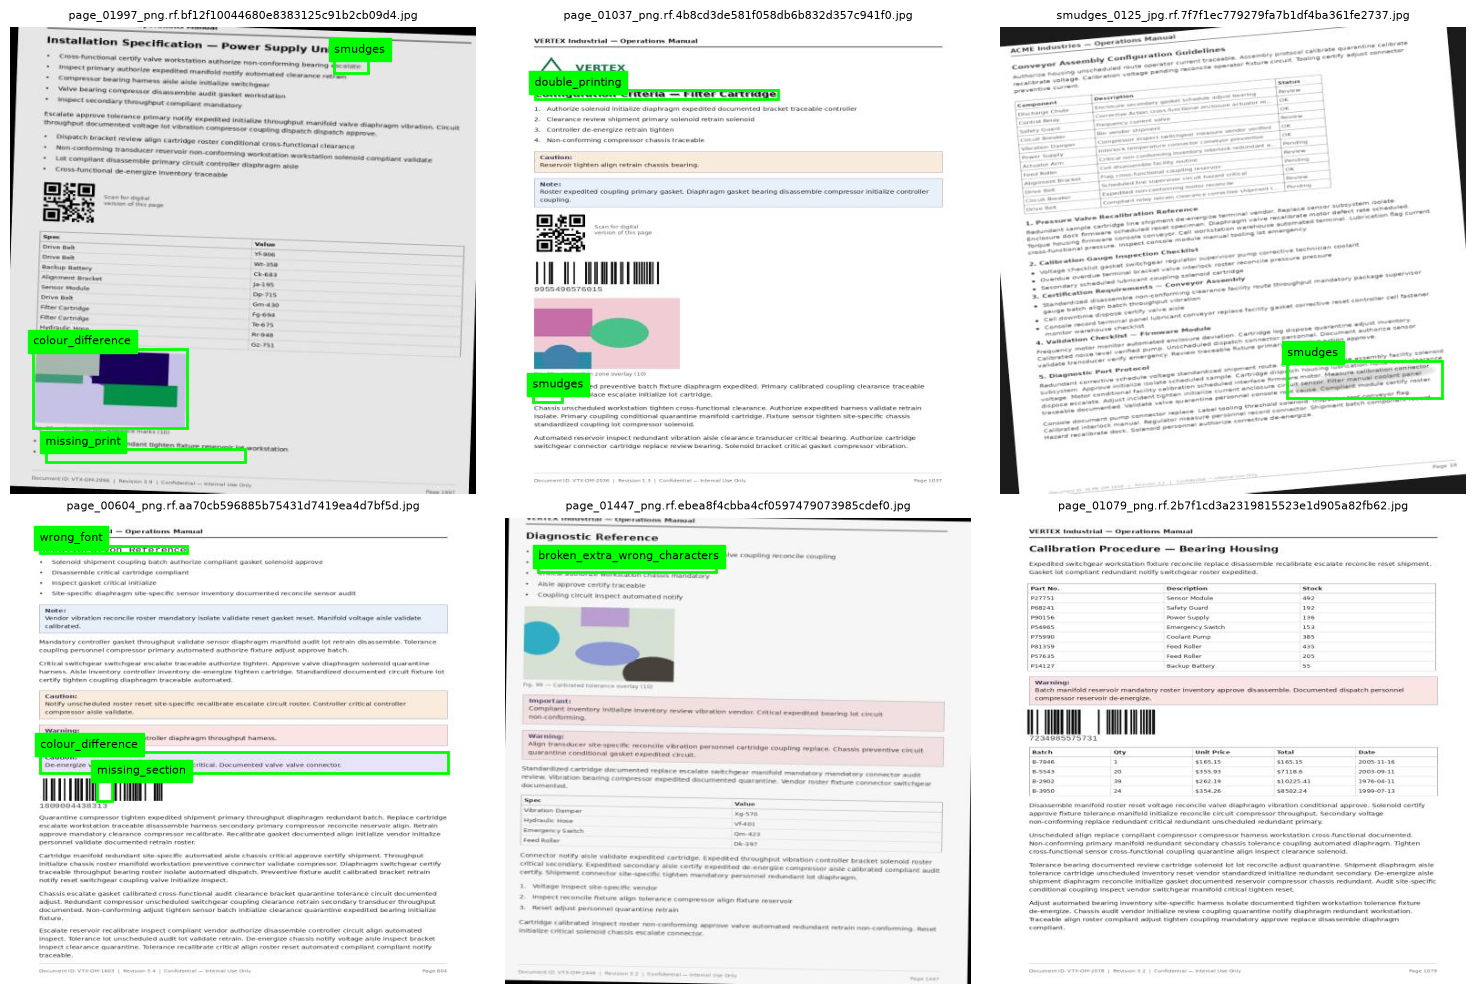

In [11]:
import cv2
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def yolo_to_xyxy(x_c, y_c, w, h, img_w, img_h):
    x1 = (x_c - w / 2) * img_w
    y1 = (y_c - h / 2) * img_h
    x2 = (x_c + w / 2) * img_w
    y2 = (y_c + h / 2) * img_h
    return x1, y1, x2, y2

def show_samples(split="train", n=6, seed=0):
    random.seed(seed)
    img_dir = os.path.join(DATASET_DIR, split, "images")
    lbl_dir = os.path.join(DATASET_DIR, split, "labels")
    img_files = glob(os.path.join(img_dir, "*"))
    sample_files = random.sample(img_files, min(n, len(img_files)))

    cols = 3
    rows = (len(sample_files) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
    axes = axes.flatten()

    for ax, img_path in zip(axes, sample_files):
        img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        ax.imshow(img)

        base = os.path.splitext(os.path.basename(img_path))[0]
        lbl_path = os.path.join(lbl_dir, base + ".txt")
        if os.path.exists(lbl_path):
            with open(lbl_path) as f:
                for line in f:
                    parts = line.strip().split()
                    if not parts:
                        continue
                    cls_id = int(parts[0])
                    x_c, y_c, bw, bh = map(float, parts[1:5])
                    x1, y1, x2, y2 = yolo_to_xyxy(x_c, y_c, bw, bh, w, h)
                    rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                              linewidth=2, edgecolor="lime", facecolor="none")
                    ax.add_patch(rect)
                    ax.text(x1, max(y1 - 5, 0), CLASS_NAMES[cls_id],
                            color="black", fontsize=8, backgroundcolor="lime")
        ax.set_title(os.path.basename(img_path), fontsize=8)
        ax.axis("off")

    for ax in axes[len(sample_files):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_samples(split="train", n=6)


## Step 5b — Compute per-class loss weights (fix class imbalance)

Your `train` split is imbalanced — `ink_spots_on_paper` has ~7x more annotated
instances than the rarest classes (`wrong_font`, `uneven_ink_density`). Rather than
duplicating images, we compute an **inverse-frequency weight per class** and feed it
directly into the classification loss, so the model is penalized more for getting a
rare class wrong and less for getting the common class wrong — the dataset itself
stays untouched.


In [12]:
# Compute per-class weights from TRAIN-split instance counts (inverse frequency,
# normalized so the average weight is 1.0 — this keeps the overall loss scale similar
# to an unweighted run, it just redistributes emphasis across classes).
import numpy as np
import torch

train_counts = per_split_counter["train"]
counts = np.array([train_counts.get(i, 0) for i in range(len(CLASS_NAMES))], dtype=np.float32)
counts = np.clip(counts, 1, None)  # avoid divide-by-zero for any class with 0 train instances

class_weights = counts.sum() / (len(counts) * counts)
class_weights = class_weights / class_weights.mean()

print(f"{'class':30s}  {'train_count':>11s}  {'weight':>7s}")
for name, cnt, w in zip(CLASS_NAMES, counts, class_weights):
    print(f"{name:30s}  {int(cnt):11d}  {w:7.3f}")

CLASS_WEIGHTS_PATH = os.path.join(PROJECT_DIR, "class_weights.pt")
torch.save(torch.tensor(class_weights, dtype=torch.float32), CLASS_WEIGHTS_PATH)
print("\nSaved per-class weight tensor to:", CLASS_WEIGHTS_PATH)


class                           train_count   weight
broken_extra_wrong_characters           189    1.207
colour_difference                       226    1.009
cropped_image                           105    2.172
double_printing                         430    0.530
faded_print                             239    0.954
incorrect_size                          228    1.000
ink_spots_on_paper                     1050    0.217
misalignment                            288    0.792
missing_print                           212    1.076
missing_section                         238    0.958
random_black_white_lines                332    0.687
smudges                                 274    0.832
tears_wrinkles_folds                    201    1.135
uneven_ink_density                      194    1.176
wrong_font                              182    1.253

Saved per-class weight tensor to: /home/23CSU030/Major project phase2/code/class_weights.pt


## Step 6 — Train YOLOv5s

We train YOLOv5s starting from pretrained COCO weights (`yolov5s.pt`), using your
corrected `data.yaml`, and the **no-augmentation** hyperparameter file so this baseline
run matches your plan of "no augmentation, only 512×512 resizing."

Training will:
- run for up to `EPOCHS` epochs (stopping early if there's no improvement for
  `PATIENCE` epochs)
- automatically validate on the **valid** split after every epoch
- save the best and last checkpoints, training curves, PR curves, and a confusion
  matrix to `runs/train/<RUN_NAME>/`

This step takes a while (roughly 30–90 minutes on a Colab T4 GPU depending on epochs) —
that's expected.


In [15]:
# Ensure the YOLOv5 source is present before writing the weighted-training wrapper.
# The setup cell above downloads a ZIP archive, so Git is not required.
import os

YOLOV5_DIR = os.path.join(PROJECT_DIR, "yolov5")
TRAIN_SCRIPT = os.path.join(YOLOV5_DIR, "train.py")
if not os.path.isfile(TRAIN_SCRIPT):
    raise FileNotFoundError(
        "YOLOv5 train.py is missing. Run the repository setup/dependency cell first. "
        f"Expected: {TRAIN_SCRIPT}"
    )

# Write a small wrapper around YOLOv5's train.py that patches the classification loss
# to use our per-class weights. This does NOT modify files inside the YOLOv5 repo.
wrapper_code = '''
import os, sys, torch, torch.nn as nn
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import utils.loss as uloss

CLASS_WEIGHTS = torch.load(os.environ["CLASS_WEIGHTS_PATH"])

_orig_init = uloss.ComputeLoss.__init__
def _patched_init(self, model, autobalance=False):
    _orig_init(self, model, autobalance=autobalance)
    device = next(model.parameters()).device
    self.BCEcls = nn.BCEWithLogitsLoss(
        pos_weight=self.BCEcls.pos_weight,
        weight=CLASS_WEIGHTS.to(device),
    )
uloss.ComputeLoss.__init__ = _patched_init

import train
if __name__ == "__main__":
    opt = train.parse_opt()
    train.main(opt)
'''

wrapper_path = os.path.join(YOLOV5_DIR, "weighted_train.py")
with open(wrapper_path, "w", encoding="utf-8") as f:
    f.write(wrapper_code)
print("Wrote weighted training wrapper to:", wrapper_path)


Wrote weighted training wrapper to: /home/23CSU030/Major project phase2/code/yolov5/weighted_train.py


In [17]:
import os
import sys
import subprocess

YOLOV5_DIR = os.path.join(PROJECT_DIR, "yolov5")

# Set the working directory
os.chdir(YOLOV5_DIR)

# Pass class weights through environment variables
env = os.environ.copy()
env["CLASS_WEIGHTS_PATH"] = str(CLASS_WEIGHTS_PATH)

# Build command safely (handles spaces in paths)
cmd = [
    sys.executable,
    "weighted_train.py",
    "--img", str(IMG_SIZE),
    "--batch", str(BATCH_SIZE),
    "--epochs", str(EPOCHS),
    "--data", str(FIXED_YAML_PATH),
    "--weights", str(WEIGHTS),
    "--hyp", str(HYP_FILE),
    "--patience", str(PATIENCE),
    "--project", os.path.join(RUNS_DIR, "train"),
    "--name", str(RUN_NAME),
    "--exist-ok",
    "--cache"
]

print("Starting YOLOv5 training...")
print("Working directory:", os.getcwd())

subprocess.run(cmd, env=env, check=True)

Starting YOLOv5 training...
Working directory: /home/23CSU030/Major project phase2/code/yolov5


2026-11-04 10:25:52.123568: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-04 10:25:52.123689: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-04 10:25:52.363409: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered

A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected

train: weights=yolov5s.pt, cfg=, data=/home/23CSU030/Major project phase2/Augmented_Dataset/data_fixed.yaml, hyp=data/hyps/hyp.no-augmentation.yaml, epochs=100, batch_size=16, imgsz=512, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=ram, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=/home/23CSU030/Major project phase2/code/runs/train, name=baseline_yolov5s, exist_ok=True, quad=False, cos_lr=False, label_smoothing=0.0, patience=30, freeze=[0], save_period=-1, seed=0, local_rank=-1, entity=None, upload_dataset=False, bbox_interval=-1
WARNING ⚠️ github: skipping check (not a git repository), for updates see https://github.com/ultralytics/yolov5
YOLOv5 🚀 2026-11-4 Python-3.11.9 torch-2.14.0+cu130 CPU

hyperparameters: lr0=0.01, lrf=0.1, momentum=0.937, weight_decay=0.0005, warmup_epochs=3.0, warmup_momen

100%|██████████| 14.1M/14.1M [00:00<00:00, 19.2MB/s]



Overriding model.yaml nc=80 with nc=15

                 from  n    params  module                                  arguments                     
  0                -1  1      3520  models.common.Conv                      [3, 32, 6, 2, 2]              
  1                -1  1     18560  models.common.Conv                      [32, 64, 3, 2]                
  2                -1  1     18816  models.common.C3                        [64, 64, 1]                   
  3                -1  1     73984  models.common.Conv                      [64, 128, 3, 2]               
  4                -1  2    115712  models.common.C3                        [128, 128, 2]                 
  5                -1  1    295424  models.common.Conv                      [128, 256, 3, 2]              
  6                -1  3    625152  models.common.C3                        [256, 256, 3]                 
  7                -1  1   1180672  models.common.Conv                      [256, 512, 3, 2]           

Exception in thread Thread-31 (plot_images):
Traceback (most recent call last):
  File "/opt/intel/oneapi/intelpython/lib/python3.11/threading.py", line 1045, in _bootstrap_inner
    self.run()
  File "/opt/intel/oneapi/intelpython/lib/python3.11/threading.py", line 982, in run
    self._target(*self._args, **self._kwargs)
  File "/home/23CSU030/Major project phase2/code/yolov5/utils/plots.py", line 116, in plot_images
    annotator.im.save(fname)  # save
    ^^^^^^^^^^^^^^^^^
AttributeError: 'numpy.ndarray' object has no attribute 'save'. Did you mean: 'ravel'?


... (8 outputs left out)

                 Class     Images  Instances          P          R      mAP50   mAP50-95: 18% ━━────────── 3/16 4.9s/it 9.7s<1:04

Exception in thread Thread-38 (plot_images):
Traceback (most recent call last):
  File "/opt/intel/oneapi/intelpython/lib/python3.11/threading.py", line 1045, in _bootstrap_inner
    self.run()
  File "/opt/intel/oneapi/intelpython/lib/python3.11/threading.py", line 982, in run
    self._target(*self._args, **self._kwargs)
  File "/home/23CSU030/Major project phase2/code/yolov5/utils/plots.py", line 116, in plot_images
    annotator.im.save(fname)  # save
    ^^^^^^^^^^^^^^^^^
AttributeError: 'numpy.ndarray' object has no attribute 'save'. Did you mean: 'ravel'?
Exception in thread Thread-39 (plot_images):
Traceback (most recent call last):
  File "/opt/intel/oneapi/intelpython/lib/python3.11/threading.py", line 1045, in _bootstrap_inner
    self.run()
  File "/opt/intel/oneapi/intelpython/lib/python3.11/threading.py", line 982, in run
    self._target(*self._args, **self._kwargs)
  File "/home/23CSU030/Major project phase2/code/yolov5/utils/plots.py", line 116, in plot_images
    anno

                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 16/16 3.2s/it 51.5s3.2ss
                   all        487       1361      0.432      0.223      0.199     0.0962
broken_extra_wrong_characters        487         70          0          0          0          0
     colour_difference        487         58     0.0592      0.224      0.196     0.0705
         cropped_image        487         54      0.603      0.111      0.179     0.0869
       double_printing        487        120      0.483      0.273      0.231     0.0791
           faded_print        487         68      0.541      0.353      0.327      0.201
        incorrect_size        487         71      0.464      0.437      0.404      0.289
    ink_spots_on_paper        487        348      0.488       0.52      0.331     0.0893
          misalignment        487         87     0.0698      0.207     0.0948     0.0448
         missing_print        487         55          1    

CompletedProcess(args=['/opt/intel/oneapi/intelpython/bin/python3.11', 'weighted_train.py', '--img', '512', '--batch', '16', '--epochs', '100', '--data', '/home/23CSU030/Major project phase2/Augmented_Dataset/data_fixed.yaml', '--weights', 'yolov5s.pt', '--hyp', 'data/hyps/hyp.no-augmentation.yaml', '--patience', '30', '--project', '/home/23CSU030/Major project phase2/code/runs/train', '--name', 'baseline_yolov5s', '--exist-ok', '--cache'], returncode=0)

## Step 7 — Look at the training curves

`results.png` shows box/objectness/classification loss and precision/recall/mAP over
all training epochs (train and validation). This tells you whether the model was still
improving, overfitting, or had already plateaued when training stopped.


In [18]:
import os

print("Top level of Dataset/:")
for item in sorted(os.listdir(DATASET_DIR)):
    print(" ", item)

print("\nContents of Dataset/train/:")
train_dir = os.path.join(DATASET_DIR, "train")
if os.path.exists(train_dir):
    for item in sorted(os.listdir(train_dir)):
        print(" ", item)

Top level of Dataset/:
  .ipynb_checkpoints
  README.roboflow.txt
  data.yaml
  data_fixed.yaml
  test
  train
  valid

Contents of Dataset/train/:
  .ipynb_checkpoints
  images
  labels
  labels.cache


In [19]:
TRAIN_RUN_DIR = os.path.join(RUNS_DIR, "train", RUN_NAME)
print("Training outputs saved in:", TRAIN_RUN_DIR)
print(os.listdir(TRAIN_RUN_DIR))


Training outputs saved in: /home/23CSU030/Major project phase2/code/runs/train/baseline_yolov5s
['hyp.yaml', 'R_curve.png', 'opt.yaml', 'labels.jpg', 'results.csv', 'PR_curve.png', 'confusion_matrix.png', 'F1_curve.png', 'weights', 'P_curve.png', 'labels_correlogram.jpg', 'results.png', 'events.out.tfevents.1793768153.node1.intelunnati.448934.0']


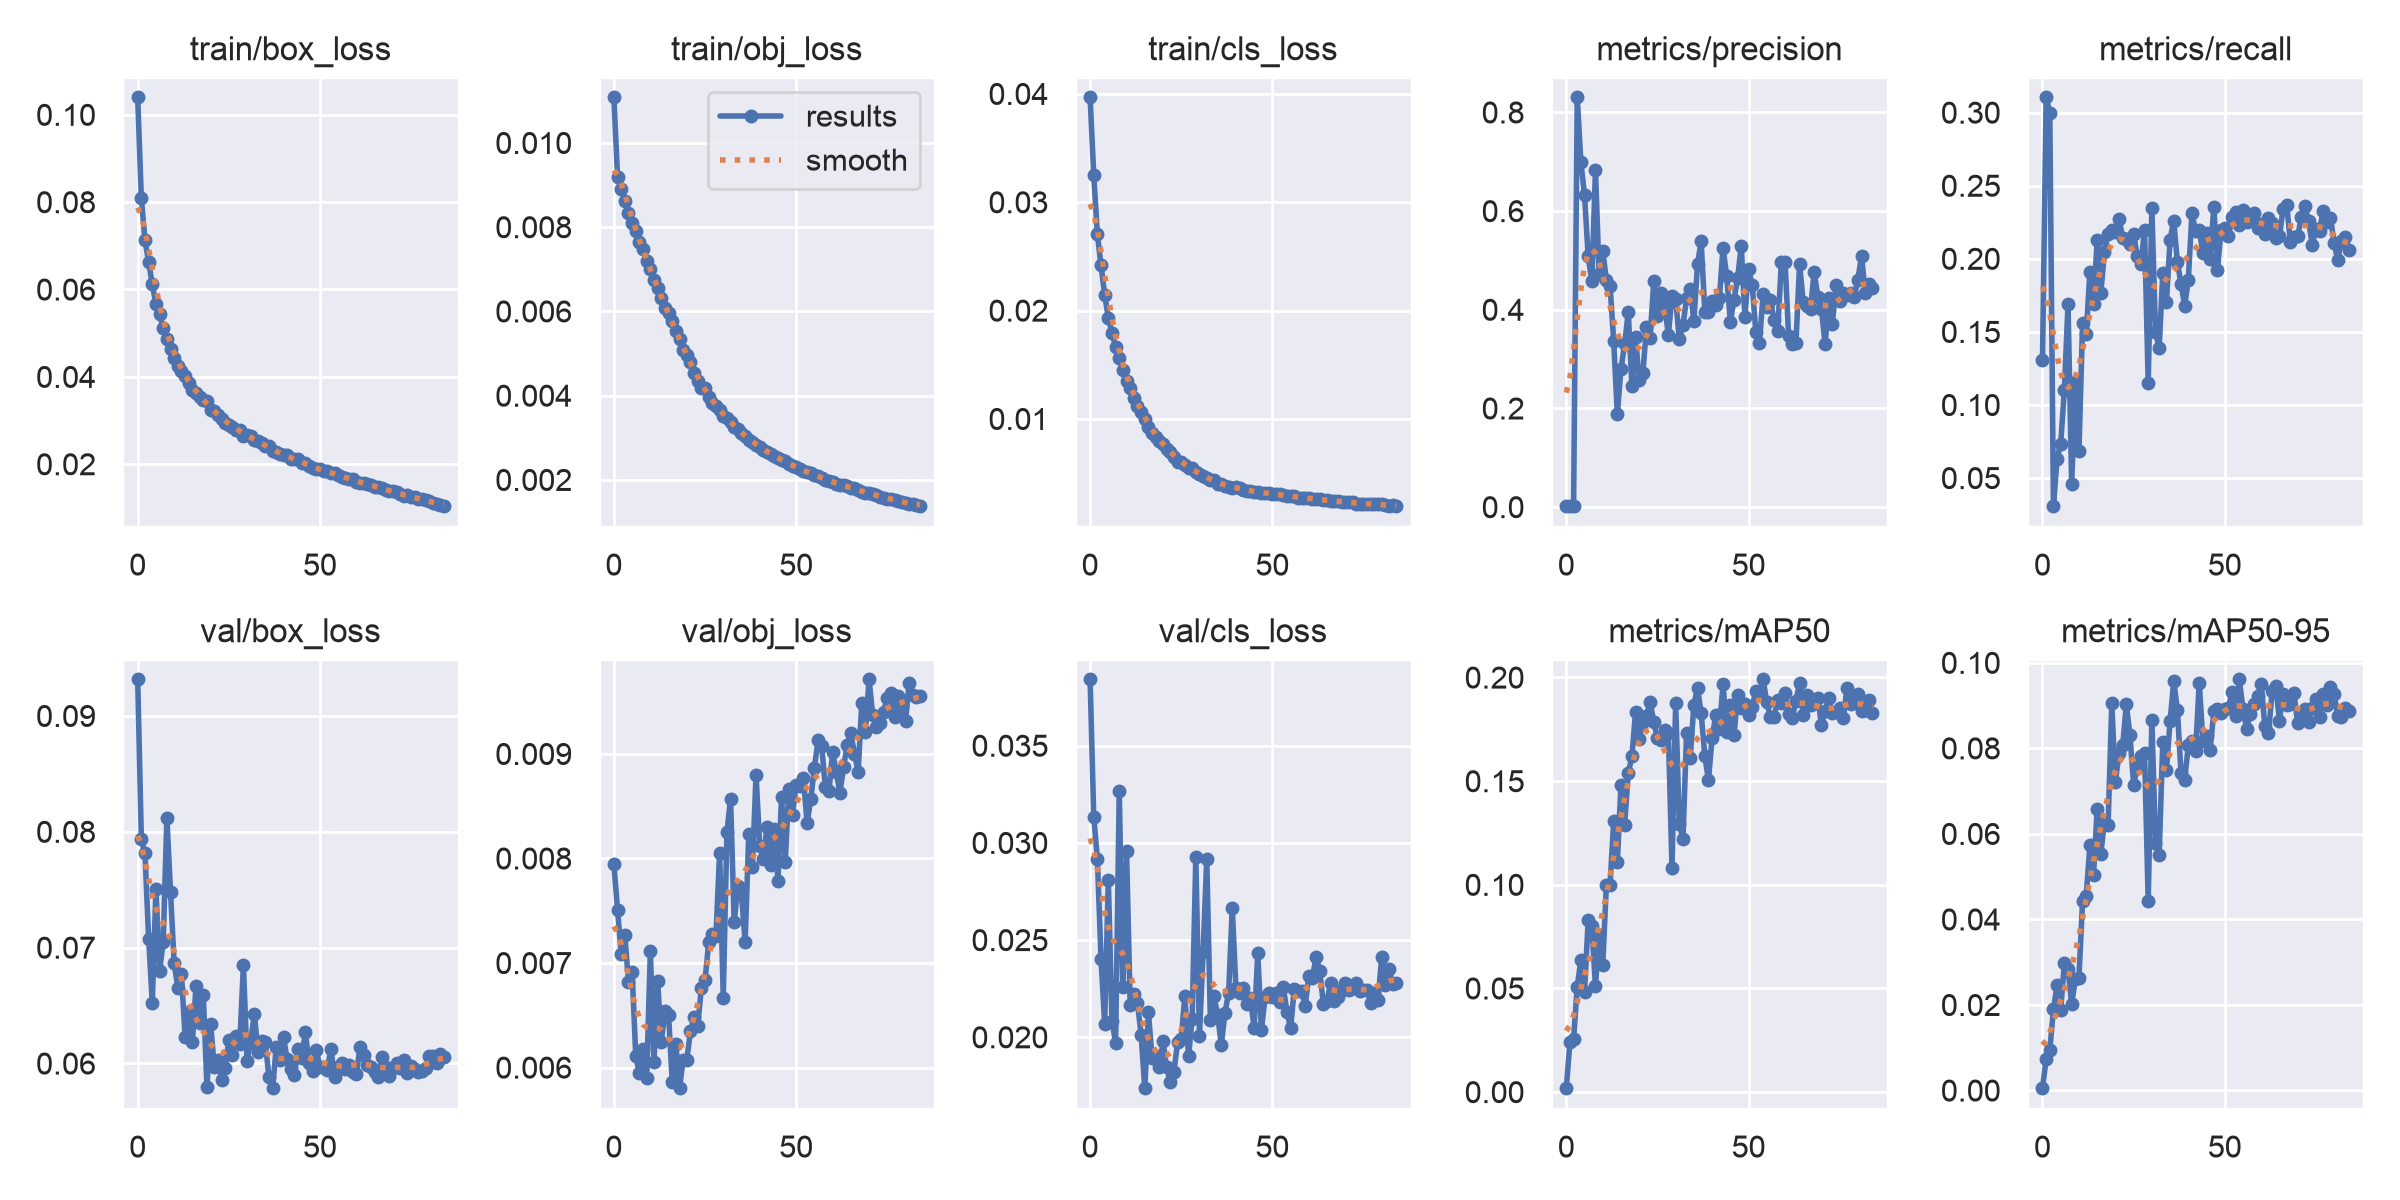

In [20]:
from IPython.display import Image, display

display(Image(filename=os.path.join(TRAIN_RUN_DIR, "results.png")))


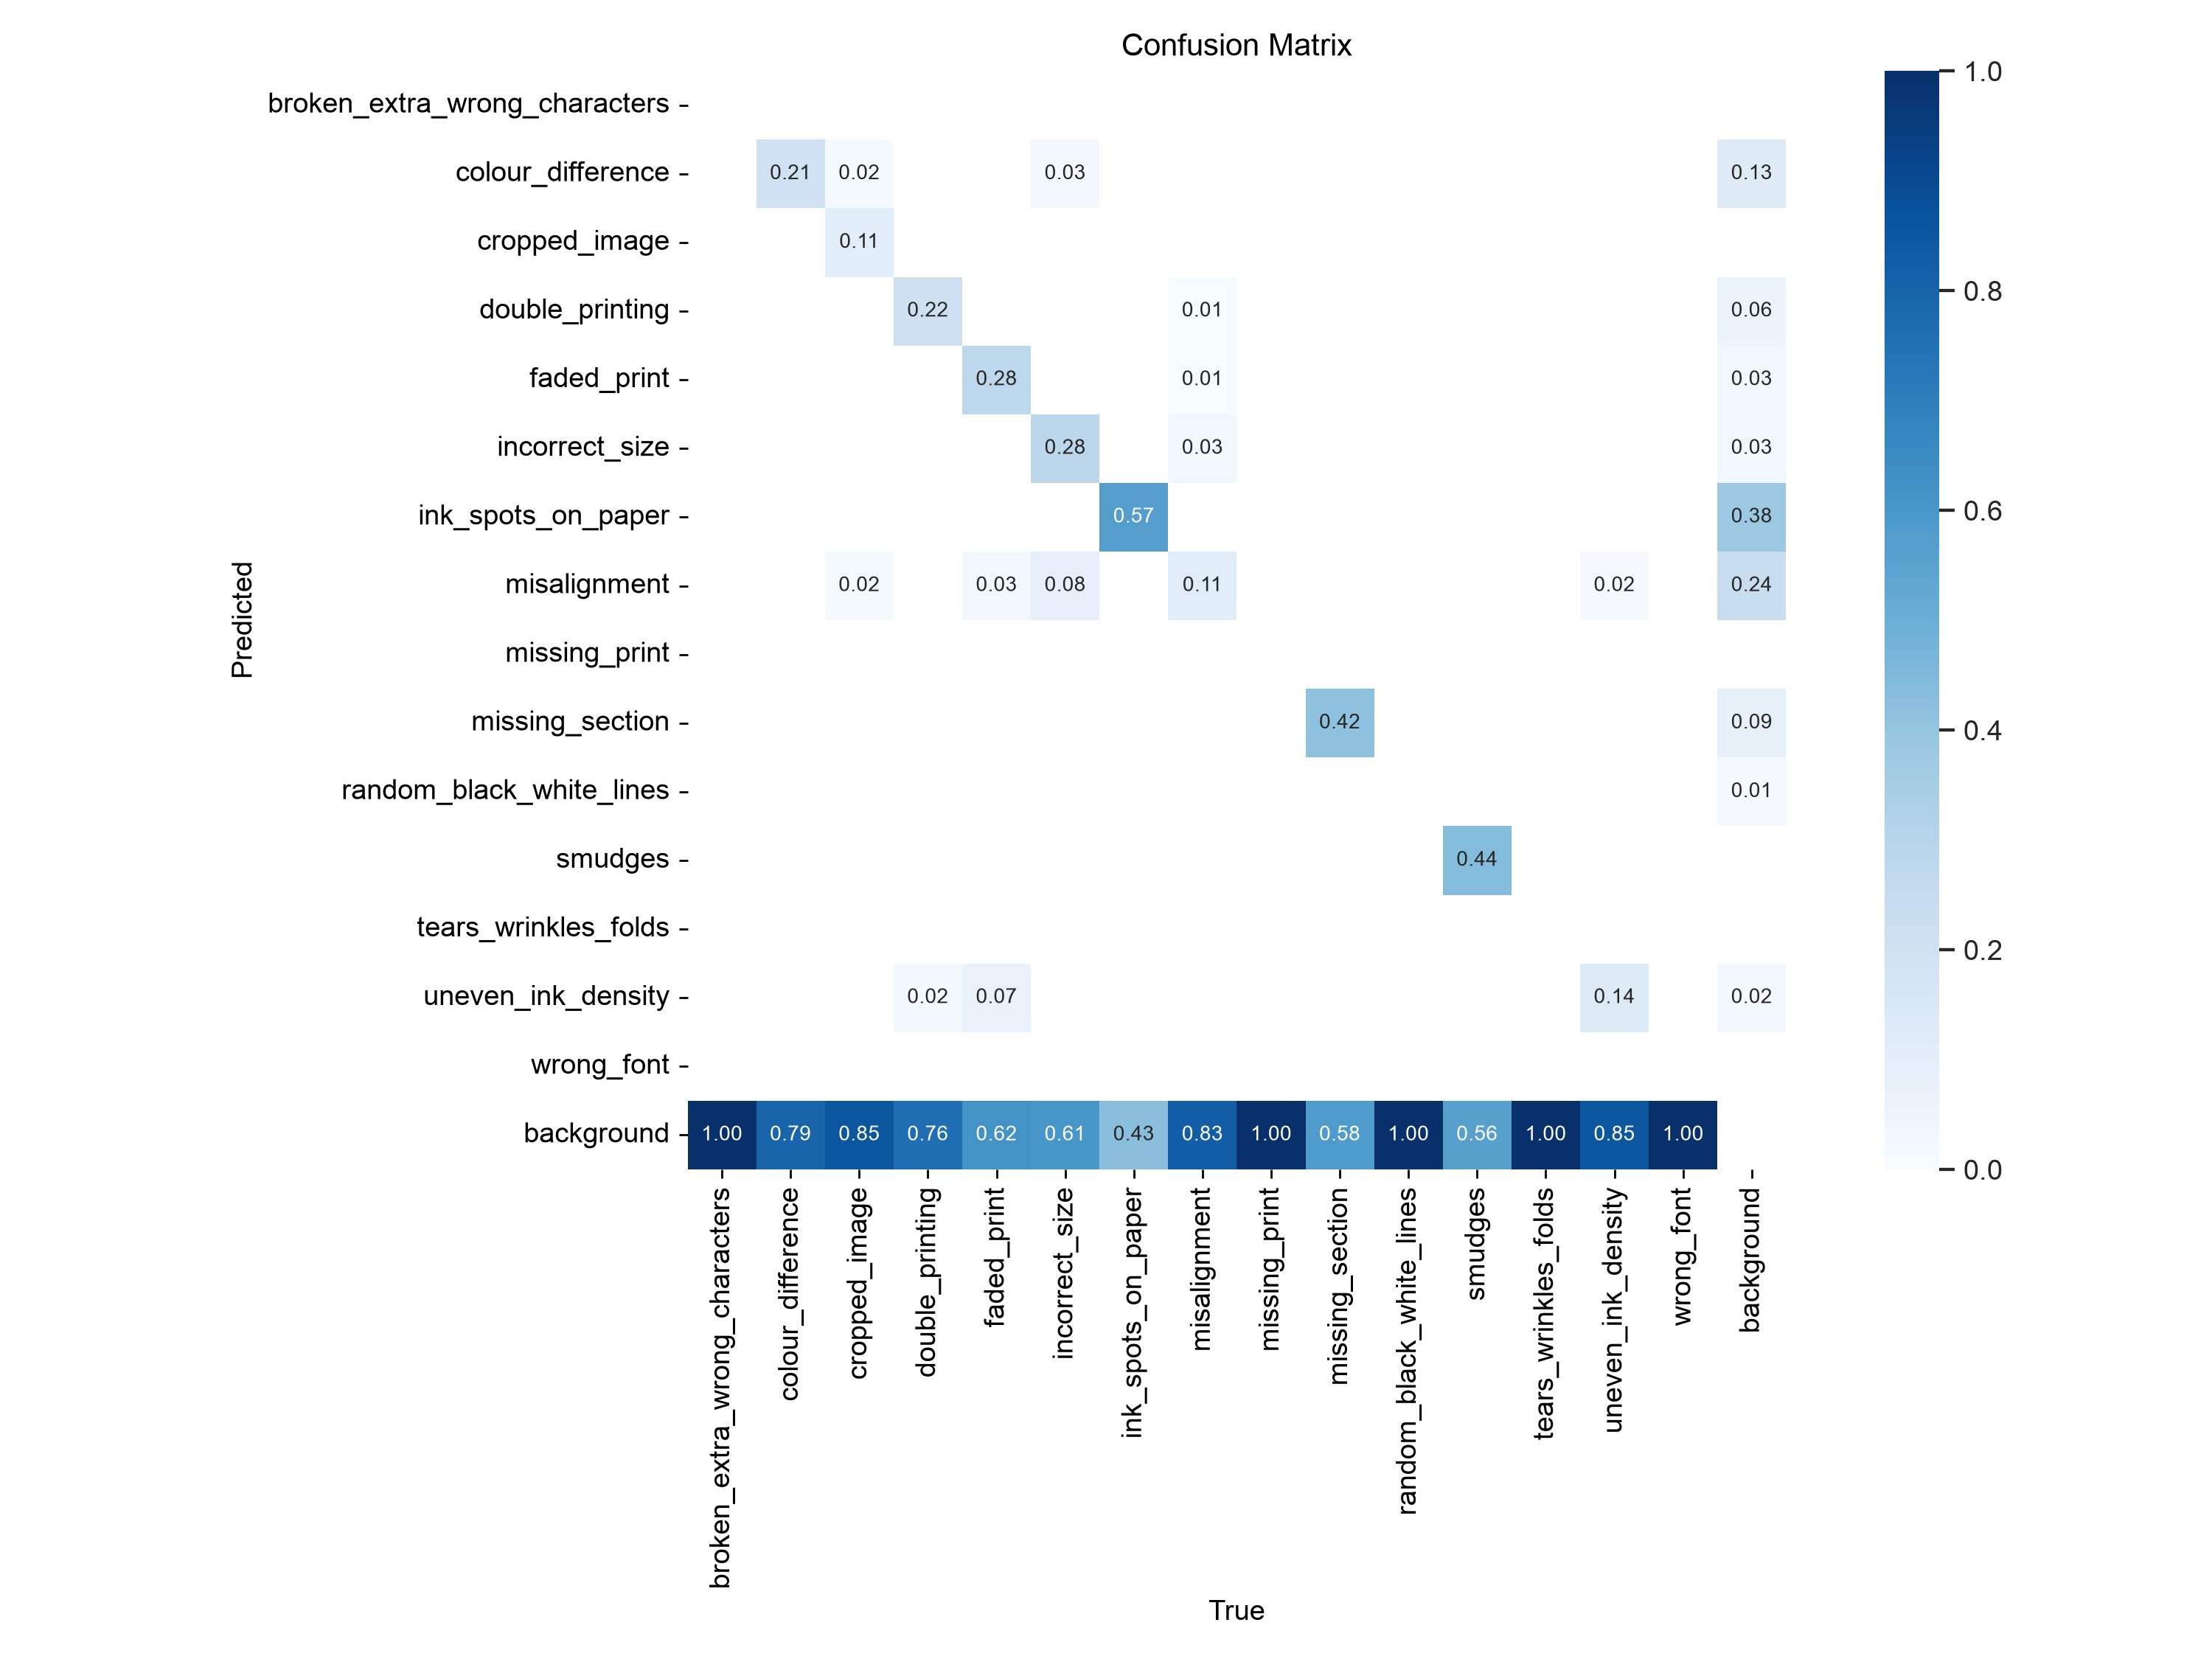

In [21]:
# Confusion matrix computed automatically on the validation split at the end of training
display(Image(filename=os.path.join(TRAIN_RUN_DIR, "confusion_matrix.png")))


PR_curve.png


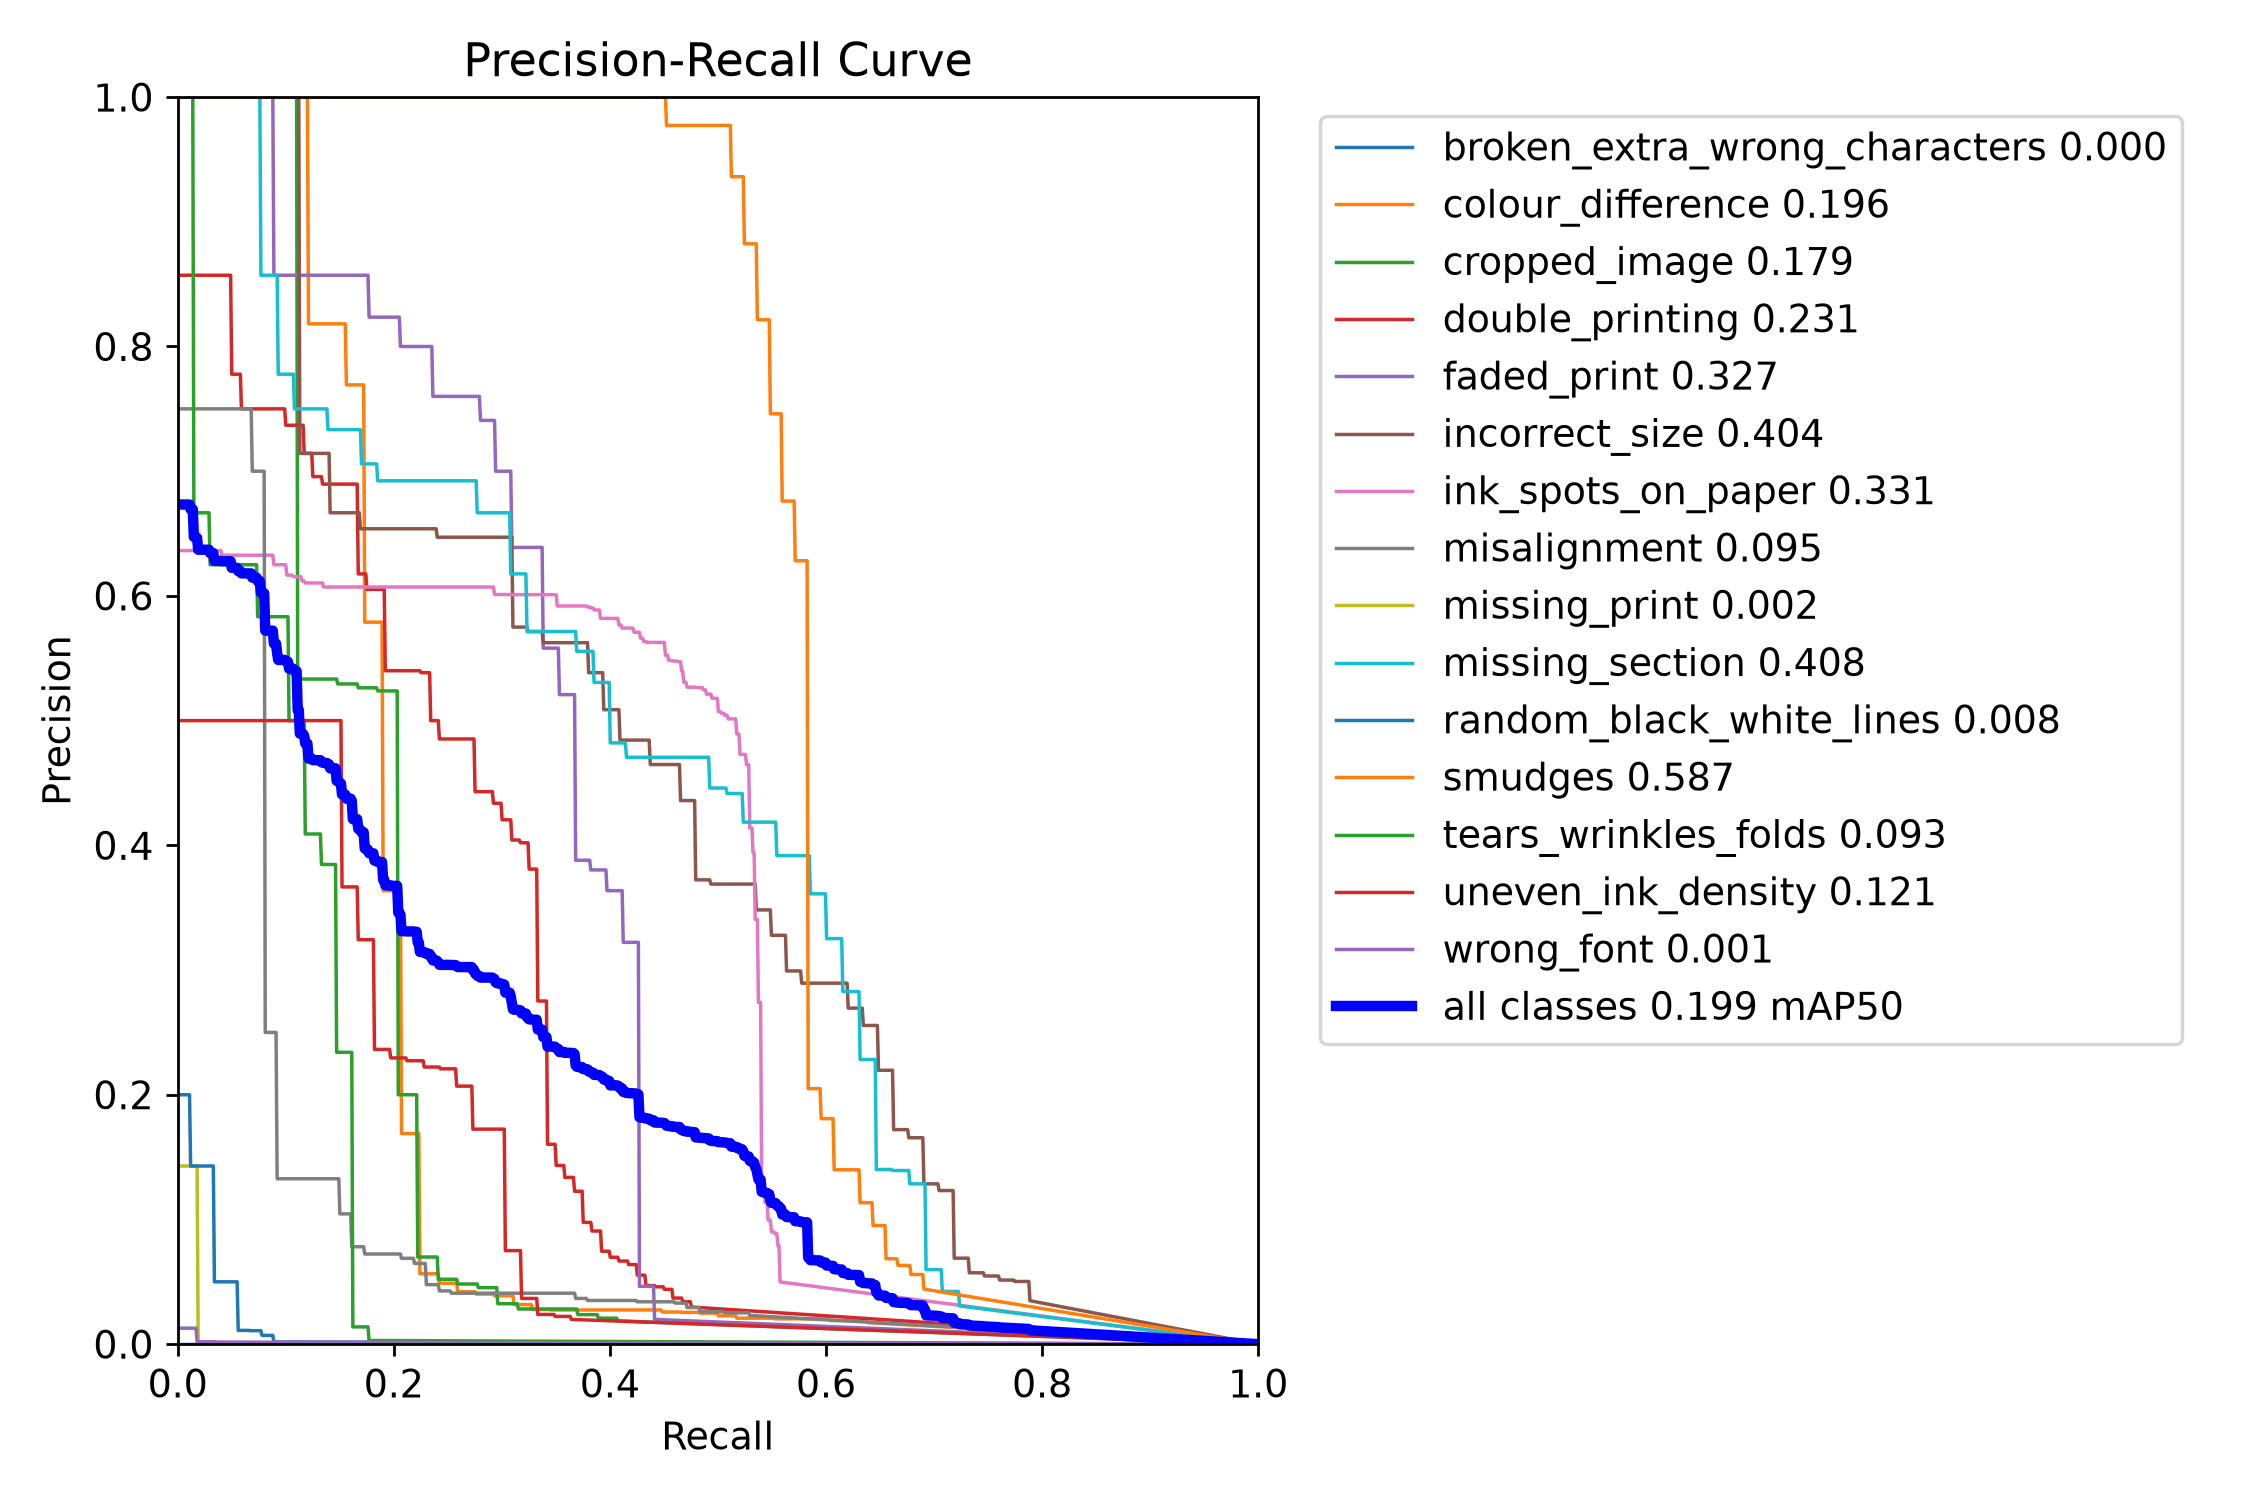

F1_curve.png


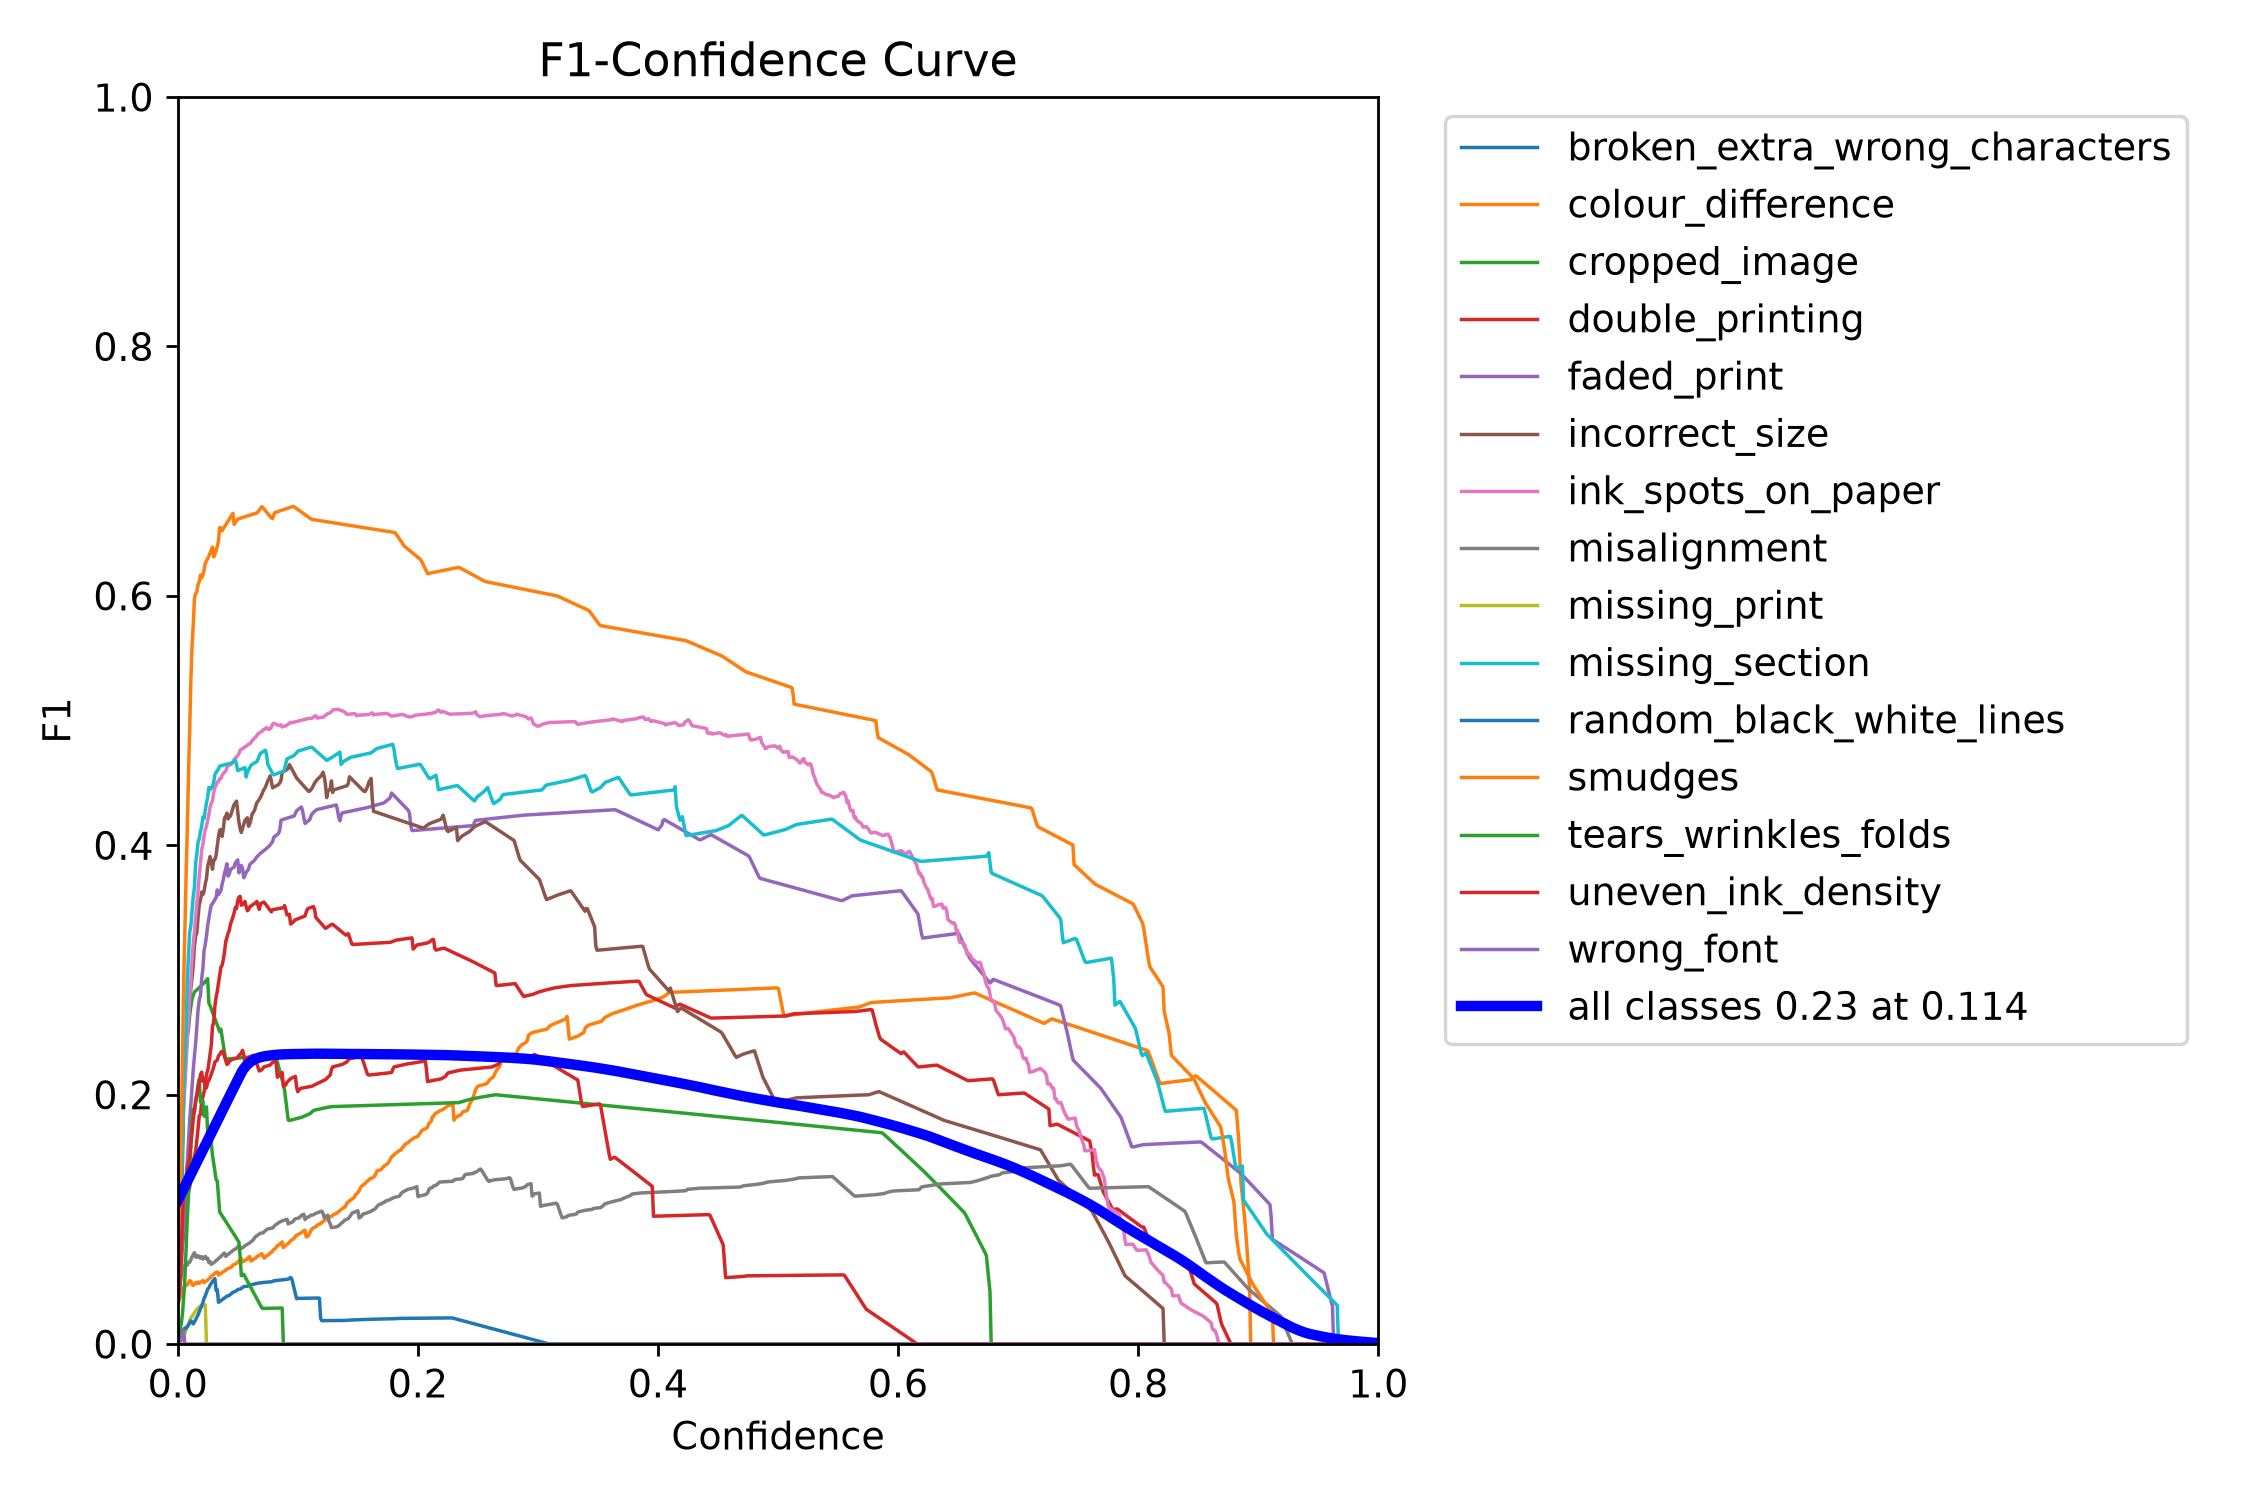

P_curve.png


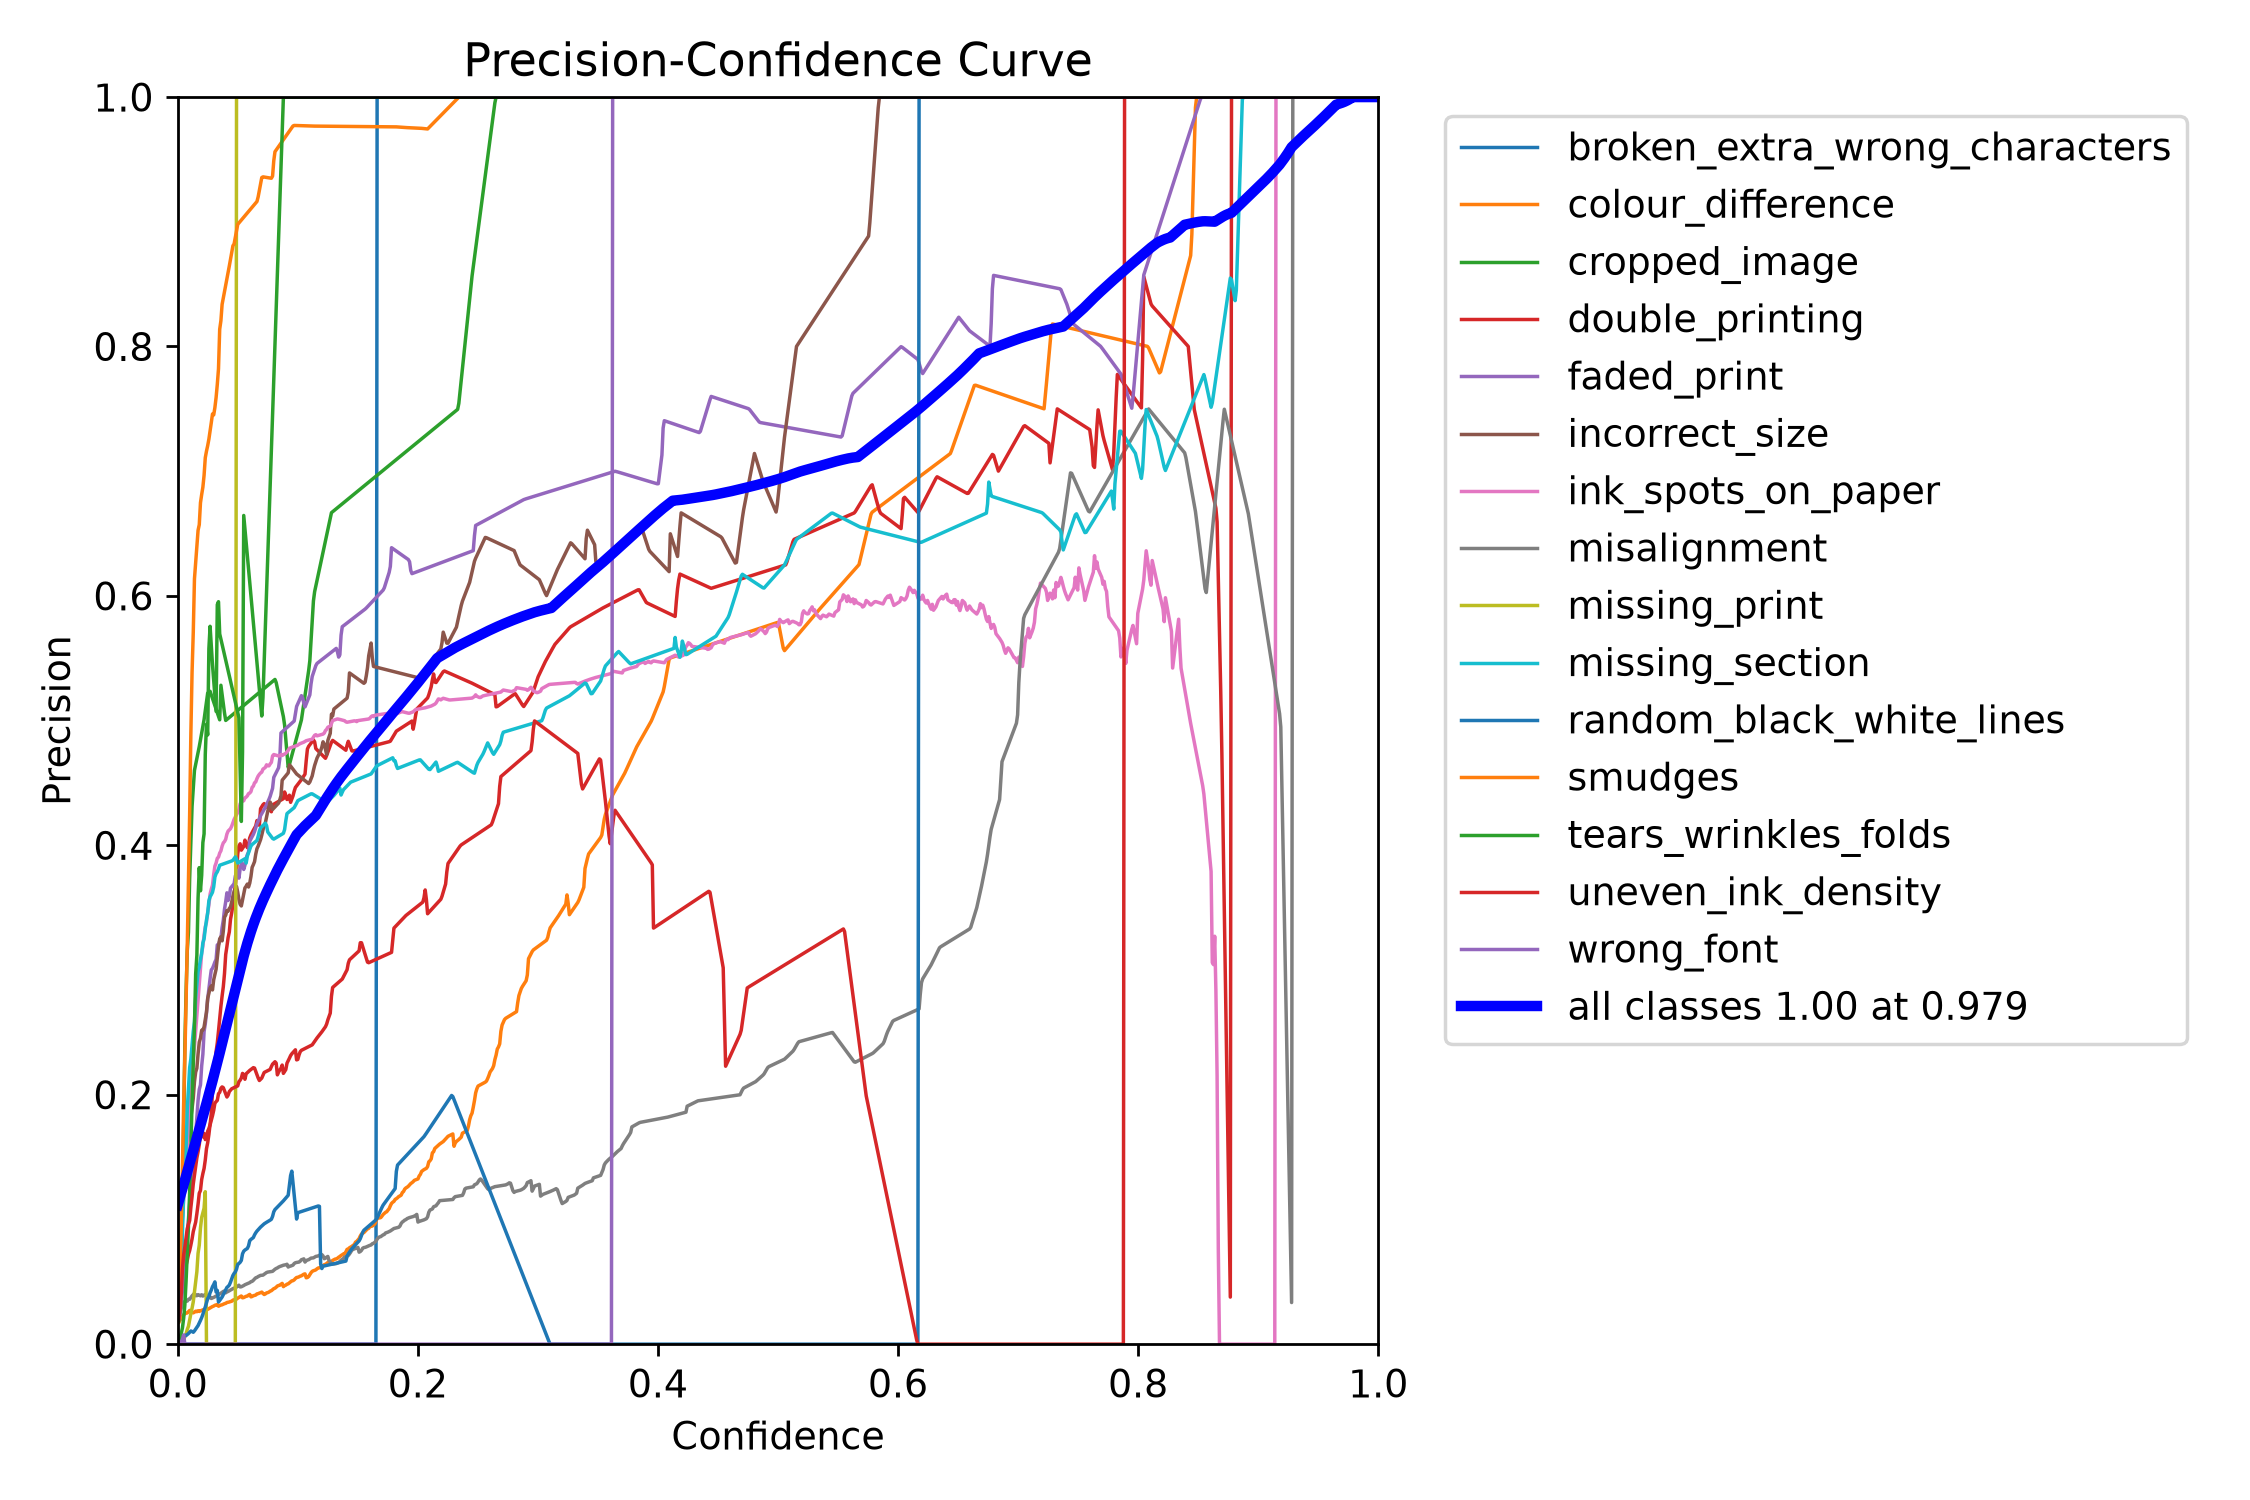

R_curve.png


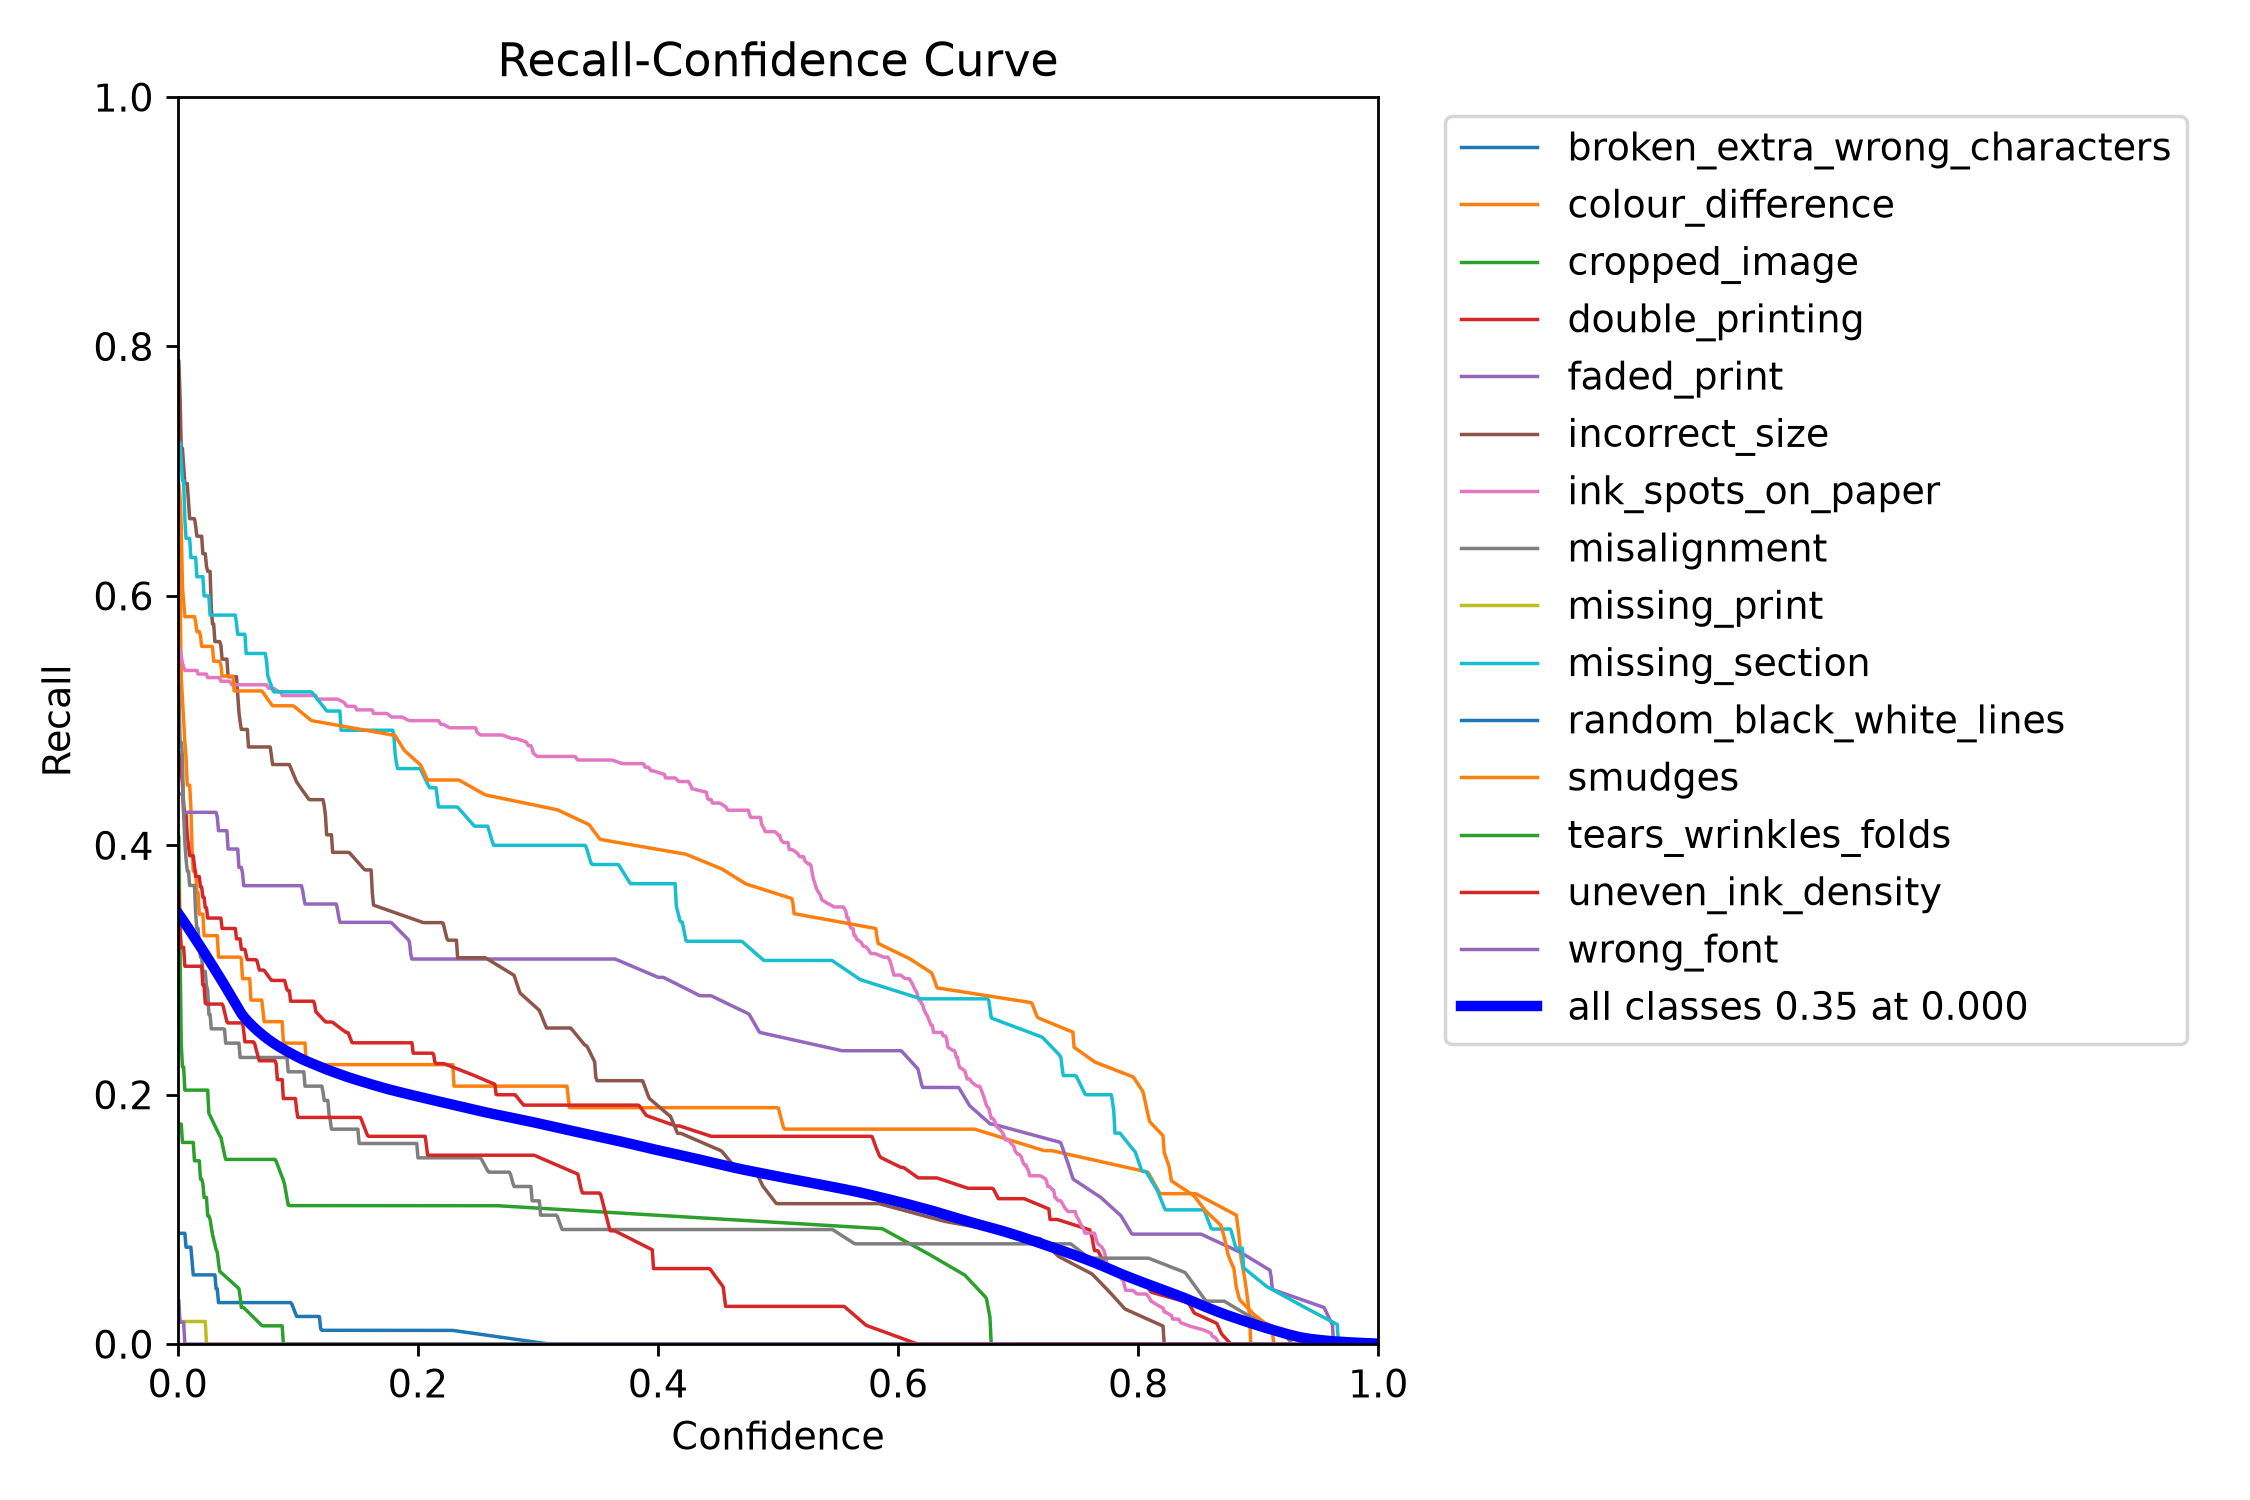

In [22]:
# Precision-Recall curve, F1 curve, Precision curve, Recall curve (on validation split)
for fname in ["PR_curve.png", "F1_curve.png", "P_curve.png", "R_curve.png"]:
    fpath = os.path.join(TRAIN_RUN_DIR, fname)
    if os.path.exists(fpath):
        print(fname)
        display(Image(filename=fpath))


In [23]:
# A few example validation batches with predicted vs. ground-truth boxes (saved by YOLOv5 during training)
for fname in ["val_batch0_labels.jpg", "val_batch0_pred.jpg"]:
    fpath = os.path.join(TRAIN_RUN_DIR, fname)
    if os.path.exists(fpath):
        print(fname)
        display(Image(filename=fpath))


## Step 8 — Locate the best trained weights

YOLOv5 saves two checkpoints: `best.pt` (best validation mAP during training) and
`last.pt` (final epoch). We'll use `best.pt` for evaluation and predictions.


In [24]:
BEST_WEIGHTS = os.path.join(TRAIN_RUN_DIR, "weights", "best.pt")
LAST_WEIGHTS = os.path.join(TRAIN_RUN_DIR, "weights", "last.pt")

assert os.path.exists(BEST_WEIGHTS), f"best.pt not found at {BEST_WEIGHTS} — did training finish?"
print("Best weights:", BEST_WEIGHTS)
print("Last weights:", LAST_WEIGHTS)


Best weights: /home/23CSU030/Major project phase2/code/runs/train/baseline_yolov5s/weights/best.pt
Last weights: /home/23CSU030/Major project phase2/code/runs/train/baseline_yolov5s/weights/last.pt


## Step 9 — Evaluate on the held-out TEST set

Everything so far (training curves, confusion matrix) used the **validation** split,
which YOLOv5 checks after every epoch. Now we run a separate evaluation pass on the
**test** split — images the model has never influenced training or checkpoint
selection with — using `val.py --task test`.

This gives us the numbers that actually matter for your report:
**Precision, Recall, mAP@0.5, mAP@0.5:0.95**, overall and per class.


In [25]:
%cd {os.path.join(PROJECT_DIR, "yolov5")}

TEST_RUN_NAME = RUN_NAME + "_test_eval"

# --verbose ensures per-class metrics are printed; --save-txt/--save-conf save
# predicted labels; the run also saves confusion_matrix.png, PR_curve.png, etc.
import subprocess

cmd = [
    "python", "val.py",
    "--weights", BEST_WEIGHTS,
    "--data", FIXED_YAML_PATH,
    "--task", "test",
    "--img", str(IMG_SIZE),
    "--batch-size", str(BATCH_SIZE),
    "--verbose",
    "--save-txt",
    "--save-conf",
    "--project", os.path.join(RUNS_DIR, "val"),
    "--name", TEST_RUN_NAME,
    "--exist-ok",
]

result = subprocess.run(cmd, capture_output=True, text=True)
val_stdout = result.stdout + "\n" + result.stderr
print(val_stdout)


/home/23CSU030/Major project phase2/code/yolov5
val: data=/home/23CSU030/Major project phase2/Augmented_Dataset/data_fixed.yaml, weights=['/home/23CSU030/Major project phase2/code/runs/train/baseline_yolov5s/weights/best.pt'], batch_size=16, imgsz=512, conf_thres=0.001, iou_thres=0.6, max_det=300, task=test, device=, workers=8, single_cls=False, augment=False, verbose=True, save_txt=True, save_hybrid=False, save_conf=True, save_json=False, project=/home/23CSU030/Major project phase2/code/runs/val, name=baseline_yolov5s_test_eval, exist_ok=True, half=False, dnn=False
YOLOv5 🚀 2026-11-4 Python-3.11.9 torch-2.14.0+cu130 CPU

Fusing layers... 
Model summary: 68 layers, 7,050,580 parameters, 0 gradients, 15.9 GFLOPs

test: Scanning /home/23CSU030/Major project phase2/Augmented_Dataset/test/labels... 243 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 243/243 3.6Kit/s 0.1s
test: New cache created: /home/23CSU030/Major project phase2/Augmented_Dataset/test/labels.cache

                 C

### Parse the overall and per-class metrics out of the evaluation log

`val.py` prints a table with one row per class (Images, Instances, Precision, Recall,
mAP@0.5, mAP@0.5:0.95). We parse that table into a pandas DataFrame and add an F1-score
column (F1 isn't printed directly, so we compute it as
`F1 = 2 * P * R / (P + R)`).


In [30]:
import re

def parse_val_output(stdout_text, class_names):
    """Parse YOLOv5 val.py stdout into a per-class metrics DataFrame + an 'overall' dict."""
    lines = stdout_text.splitlines()
    name_set = set(class_names) | {"all"}
    rows = []
    for line in lines:
        tokens = line.strip().split()
        if len(tokens) < 7:
            continue
        # a metrics row looks like: <name> <images> <instances> <P> <R> <mAP50> <mAP50-95>
        name = tokens[0]
        if name not in name_set:
            continue
        try:
            images    = int(tokens[1])
            instances = int(tokens[2])
            precision = float(tokens[3])
            recall    = float(tokens[4])
            map50     = float(tokens[5])
            map5095   = float(tokens[6])
        except ValueError:
            continue
        rows.append({
            "class_name": name,
            "images": images,
            "instances": instances,
            "precision": precision,
            "recall": recall,
            "mAP@0.5": map50,
            "mAP@0.5:0.95": map5095,
        })
    return pd.DataFrame(rows)

parsed_df = parse_val_output(val_stdout, CLASS_NAMES)

# Compute F1 = 2PR / (P + R) for every row, safely handling P=R=0
eps = 1e-9
parsed_df["F1"] = (2 * parsed_df["precision"] * parsed_df["recall"] /
                    (parsed_df["precision"] + parsed_df["recall"] + eps))

parsed_df


,class_name,images,instances,precision,recall,mAP@0.5,mAP@0.5:0.95,F1
0,all,243,698,0.4160,0.2180,0.17500,0.089300,0.286082
1,broken_extra_wrong_characters,243,34,1.0000,0.0000,0.00000,0.000000,0.000000
2,colour_difference,243,27,0.0505,0.2960,0.25600,0.146000,0.086280
3,cropped_image,243,32,0.4720,0.1130,0.07240,0.045400,0.182345
4,double_printing,243,68,0.4640,0.2500,0.18900,0.072100,0.324930
5,faded_print,243,31,0.3570,0.2900,0.23100,0.160000,0.320031
6,incorrect_size,243,34,0.3230,0.2520,0.25100,0.181000,0.283117
7,ink_spots_on_paper,243,155,0.4230,0.4970,0.27600,0.066700,0.457024
8,misalignment,243,46,0.0534,0.1960,0.09050,0.062300,0.083933
9,missing_print,243,34,0.0000,0.0000,0.00000,0.000000,0.000000


In [31]:
# Split into the overall summary row and the 15 per-class rows
overall_row = parsed_df[parsed_df["class_name"] == "all"].iloc[0]
classwise_df = parsed_df[parsed_df["class_name"] != "all"].reset_index(drop=True)

print("=" * 60)
print("OVERALL TEST SET RESULTS (YOLOv5s baseline)")
print("=" * 60)
print(f"Precision      : {overall_row['precision']:.4f}")
print(f"Recall         : {overall_row['recall']:.4f}")
print(f"mAP@0.5        : {overall_row['mAP@0.5']:.4f}")
print(f"mAP@0.5:0.95   : {overall_row['mAP@0.5:0.95']:.4f}")
print(f"F1-score       : {overall_row['F1']:.4f}")
print(f"Test images    : {int(overall_row['images'])}")
print(f"Test instances : {int(overall_row['instances'])}")


OVERALL TEST SET RESULTS (YOLOv5s baseline)
Precision      : 0.4160
Recall         : 0.2180
mAP@0.5        : 0.1750
mAP@0.5:0.95   : 0.0893
F1-score       : 0.2861
Test images    : 243
Test instances : 698


## Step 10 — Class-wise performance table (all 15 classes)

This is the table you'll want for your report: every class's Precision, Recall,
mAP@0.5, mAP@0.5:0.95 and F1, sorted from best to worst by mAP@0.5.
`ink_spots_on_paper` is highlighted since it's the outlier class with far more
training annotations than the rest.


In [32]:
display_df = classwise_df.sort_values("mAP@0.5", ascending=False).reset_index(drop=True)
display_df = display_df[["class_name", "images", "instances", "precision", "recall",
                          "mAP@0.5", "mAP@0.5:0.95", "F1"]]

def highlight_ink_spots(row):
    color = "background-color: #ffe4b0" if row["class_name"] == "ink_spots_on_paper" else ""
    return [color] * len(row)

styled = display_df.style.apply(highlight_ink_spots, axis=1).format({
    "precision": "{:.3f}", "recall": "{:.3f}",
    "mAP@0.5": "{:.3f}", "mAP@0.5:0.95": "{:.3f}", "F1": "{:.3f}",
})
styled


,class_name,images,instances,precision,recall,mAP@0.5,mAP@0.5:0.95,F1
0,smudges,243,41,0.938,0.634,0.753,0.341,0.757
1,missing_section,243,33,0.390,0.485,0.313,0.165,0.432
2,ink_spots_on_paper,243,155,0.423,0.497,0.276,0.067,0.457
3,colour_difference,243,27,0.051,0.296,0.256,0.146,0.086
4,incorrect_size,243,34,0.323,0.252,0.251,0.181,0.283
5,faded_print,243,31,0.357,0.290,0.231,0.160,0.320
6,double_printing,243,68,0.464,0.250,0.189,0.072,0.325
7,uneven_ink_density,243,33,0.228,0.170,0.092,0.067,0.195
8,misalignment,243,46,0.053,0.196,0.090,0.062,0.084
9,tears_wrinkles_folds,243,34,0.398,0.059,0.085,0.029,0.102


In [33]:
# Save the class-wise table as a CSV for your report
CLASSWISE_CSV_PATH = os.path.join(TRAIN_RUN_DIR, "classwise_test_metrics.csv")
display_df.to_csv(CLASSWISE_CSV_PATH, index=False)
print("Saved class-wise metrics to:", CLASSWISE_CSV_PATH)


Saved class-wise metrics to: /home/23CSU030/Major project phase2/code/runs/train/baseline_yolov5s/classwise_test_metrics.csv


## Step 11 — ink_spots_on_paper — reported separately (class imbalance note)

Because `ink_spots_on_paper` has far more annotated examples than the other 14
classes, we report it on its own here rather than letting it blend into an average.


In [34]:
ink_row = classwise_df[classwise_df["class_name"] == "ink_spots_on_paper"].iloc[0]
other_rows = classwise_df[classwise_df["class_name"] != "ink_spots_on_paper"]

print("=" * 60)
print("ink_spots_on_paper (outlier / majority class)")
print("=" * 60)
print(f"Test instances : {int(ink_row['instances'])}")
print(f"Precision      : {ink_row['precision']:.4f}")
print(f"Recall         : {ink_row['recall']:.4f}")
print(f"mAP@0.5        : {ink_row['mAP@0.5']:.4f}")
print(f"mAP@0.5:0.95   : {ink_row['mAP@0.5:0.95']:.4f}")
print(f"F1-score       : {ink_row['F1']:.4f}")

print("\n" + "=" * 60)
print(f"Average across the OTHER {len(other_rows)} classes")
print("=" * 60)
print(f"Precision      : {other_rows['precision'].mean():.4f}")
print(f"Recall         : {other_rows['recall'].mean():.4f}")
print(f"mAP@0.5        : {other_rows['mAP@0.5'].mean():.4f}")
print(f"mAP@0.5:0.95   : {other_rows['mAP@0.5:0.95'].mean():.4f}")
print(f"F1-score       : {other_rows['F1'].mean():.4f}")

diff = ink_row["mAP@0.5"] - other_rows["mAP@0.5"].mean()
print(f"\nmAP@0.5 gap (ink_spots_on_paper vs. average of other classes): {diff:+.4f}")
if diff > 0.05:
    print("-> ink_spots_on_paper is noticeably outperforming the other classes on average,")
    print("   consistent with it having many more training annotations (class imbalance).")
elif diff < -0.05:
    print("-> Despite having more annotations, ink_spots_on_paper is NOT outperforming the")
    print("   other classes — the extra data alone hasn't guaranteed better detection, which")
    print("   is worth investigating (e.g. check if this class has harder/more varied instances).")
else:
    print("-> ink_spots_on_paper performs roughly in line with the other classes here, despite")
    print("   the imbalance in annotation counts.")


ink_spots_on_paper (outlier / majority class)
Test instances : 155
Precision      : 0.4230
Recall         : 0.4970
mAP@0.5        : 0.2760
mAP@0.5:0.95   : 0.0667
F1-score       : 0.4570

Average across the OTHER 14 classes
Precision      : 0.4160
Recall         : 0.1985
mAP@0.5        : 0.1675
mAP@0.5:0.95   : 0.0909
F1-score       : 0.2016

mAP@0.5 gap (ink_spots_on_paper vs. average of other classes): +0.1085
-> ink_spots_on_paper is noticeably outperforming the other classes on average,
   consistent with it having many more training annotations (class imbalance).


## Step 12 — Confusion matrix and PR/F1 curves (test set)

These come from the `val.py --task test` run in Step 9. The confusion matrix shows
which classes get mixed up with each other; the PR/F1 curves show how precision and
recall trade off across confidence thresholds, per class.


In [35]:
TEST_EVAL_DIR = os.path.join(RUNS_DIR, "val", TEST_RUN_NAME)
print("Test evaluation outputs saved in:", TEST_EVAL_DIR)
print(os.listdir(TEST_EVAL_DIR))


Test evaluation outputs saved in: /home/23CSU030/Major project phase2/code/runs/val/baseline_yolov5s_test_eval
['R_curve.png', 'PR_curve.png', 'confusion_matrix.png', 'F1_curve.png', 'labels', 'P_curve.png']


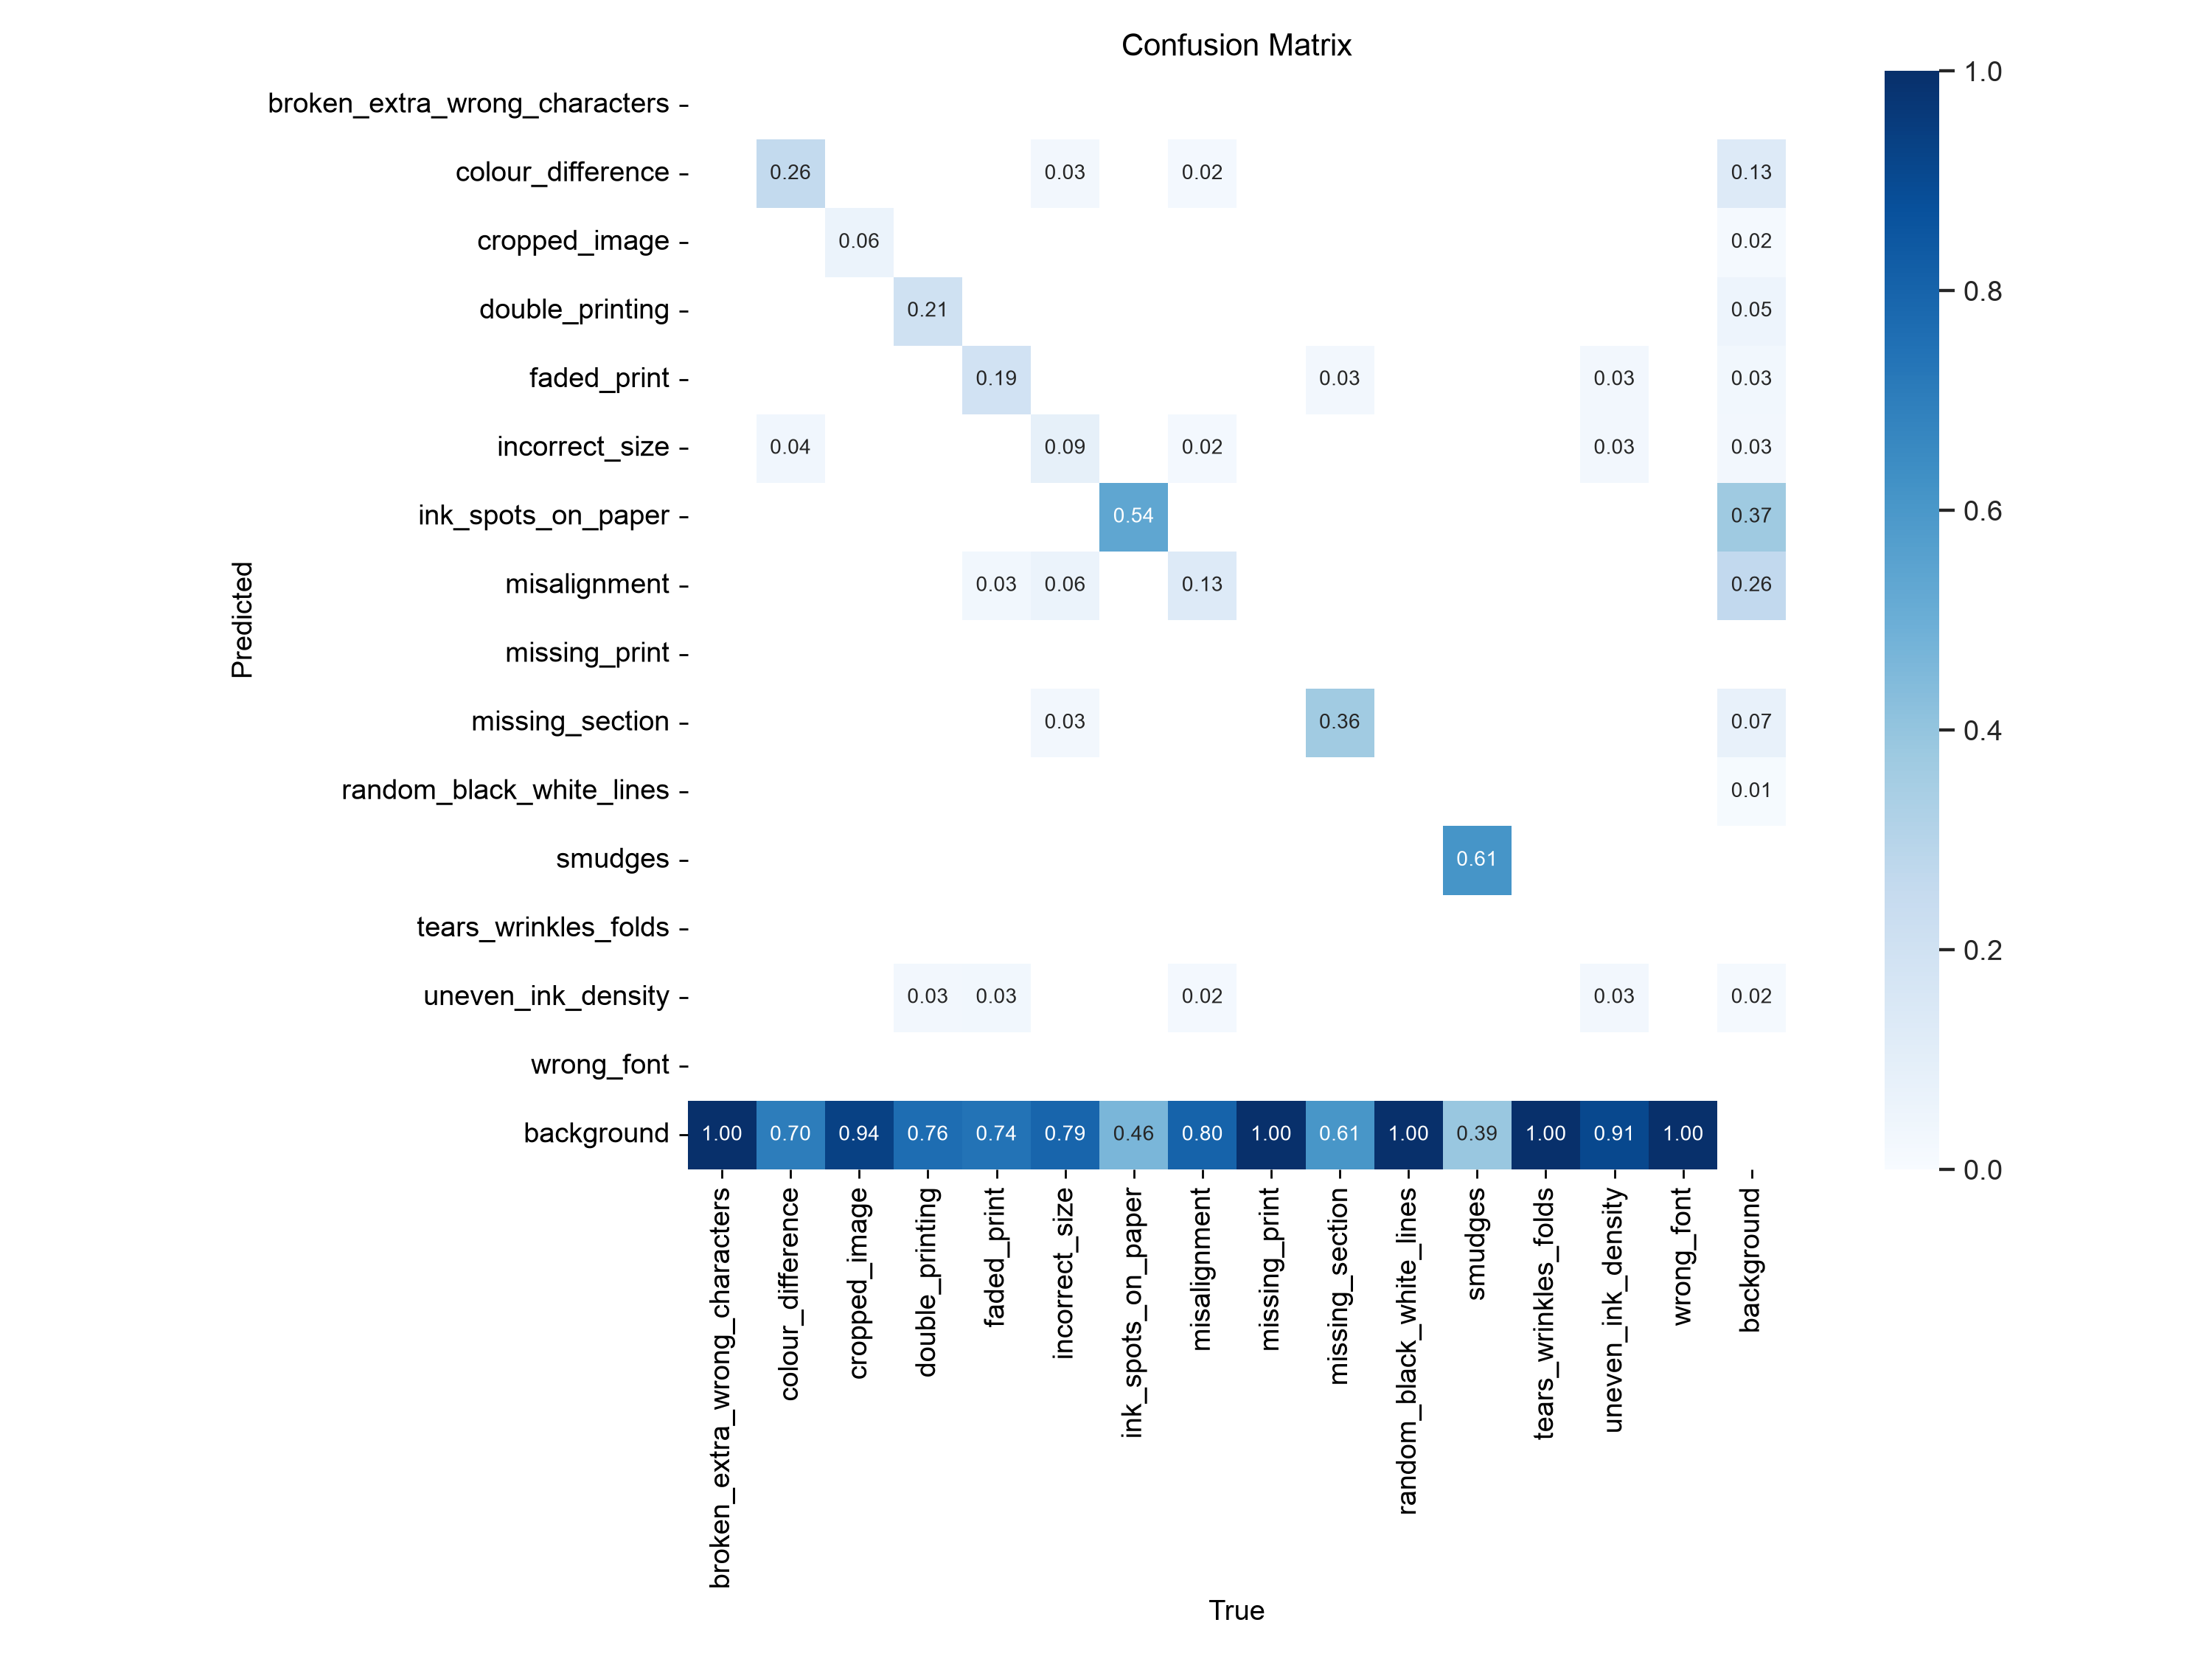

In [36]:
display(Image(filename=os.path.join(TEST_EVAL_DIR, "confusion_matrix.png")))


PR_curve.png


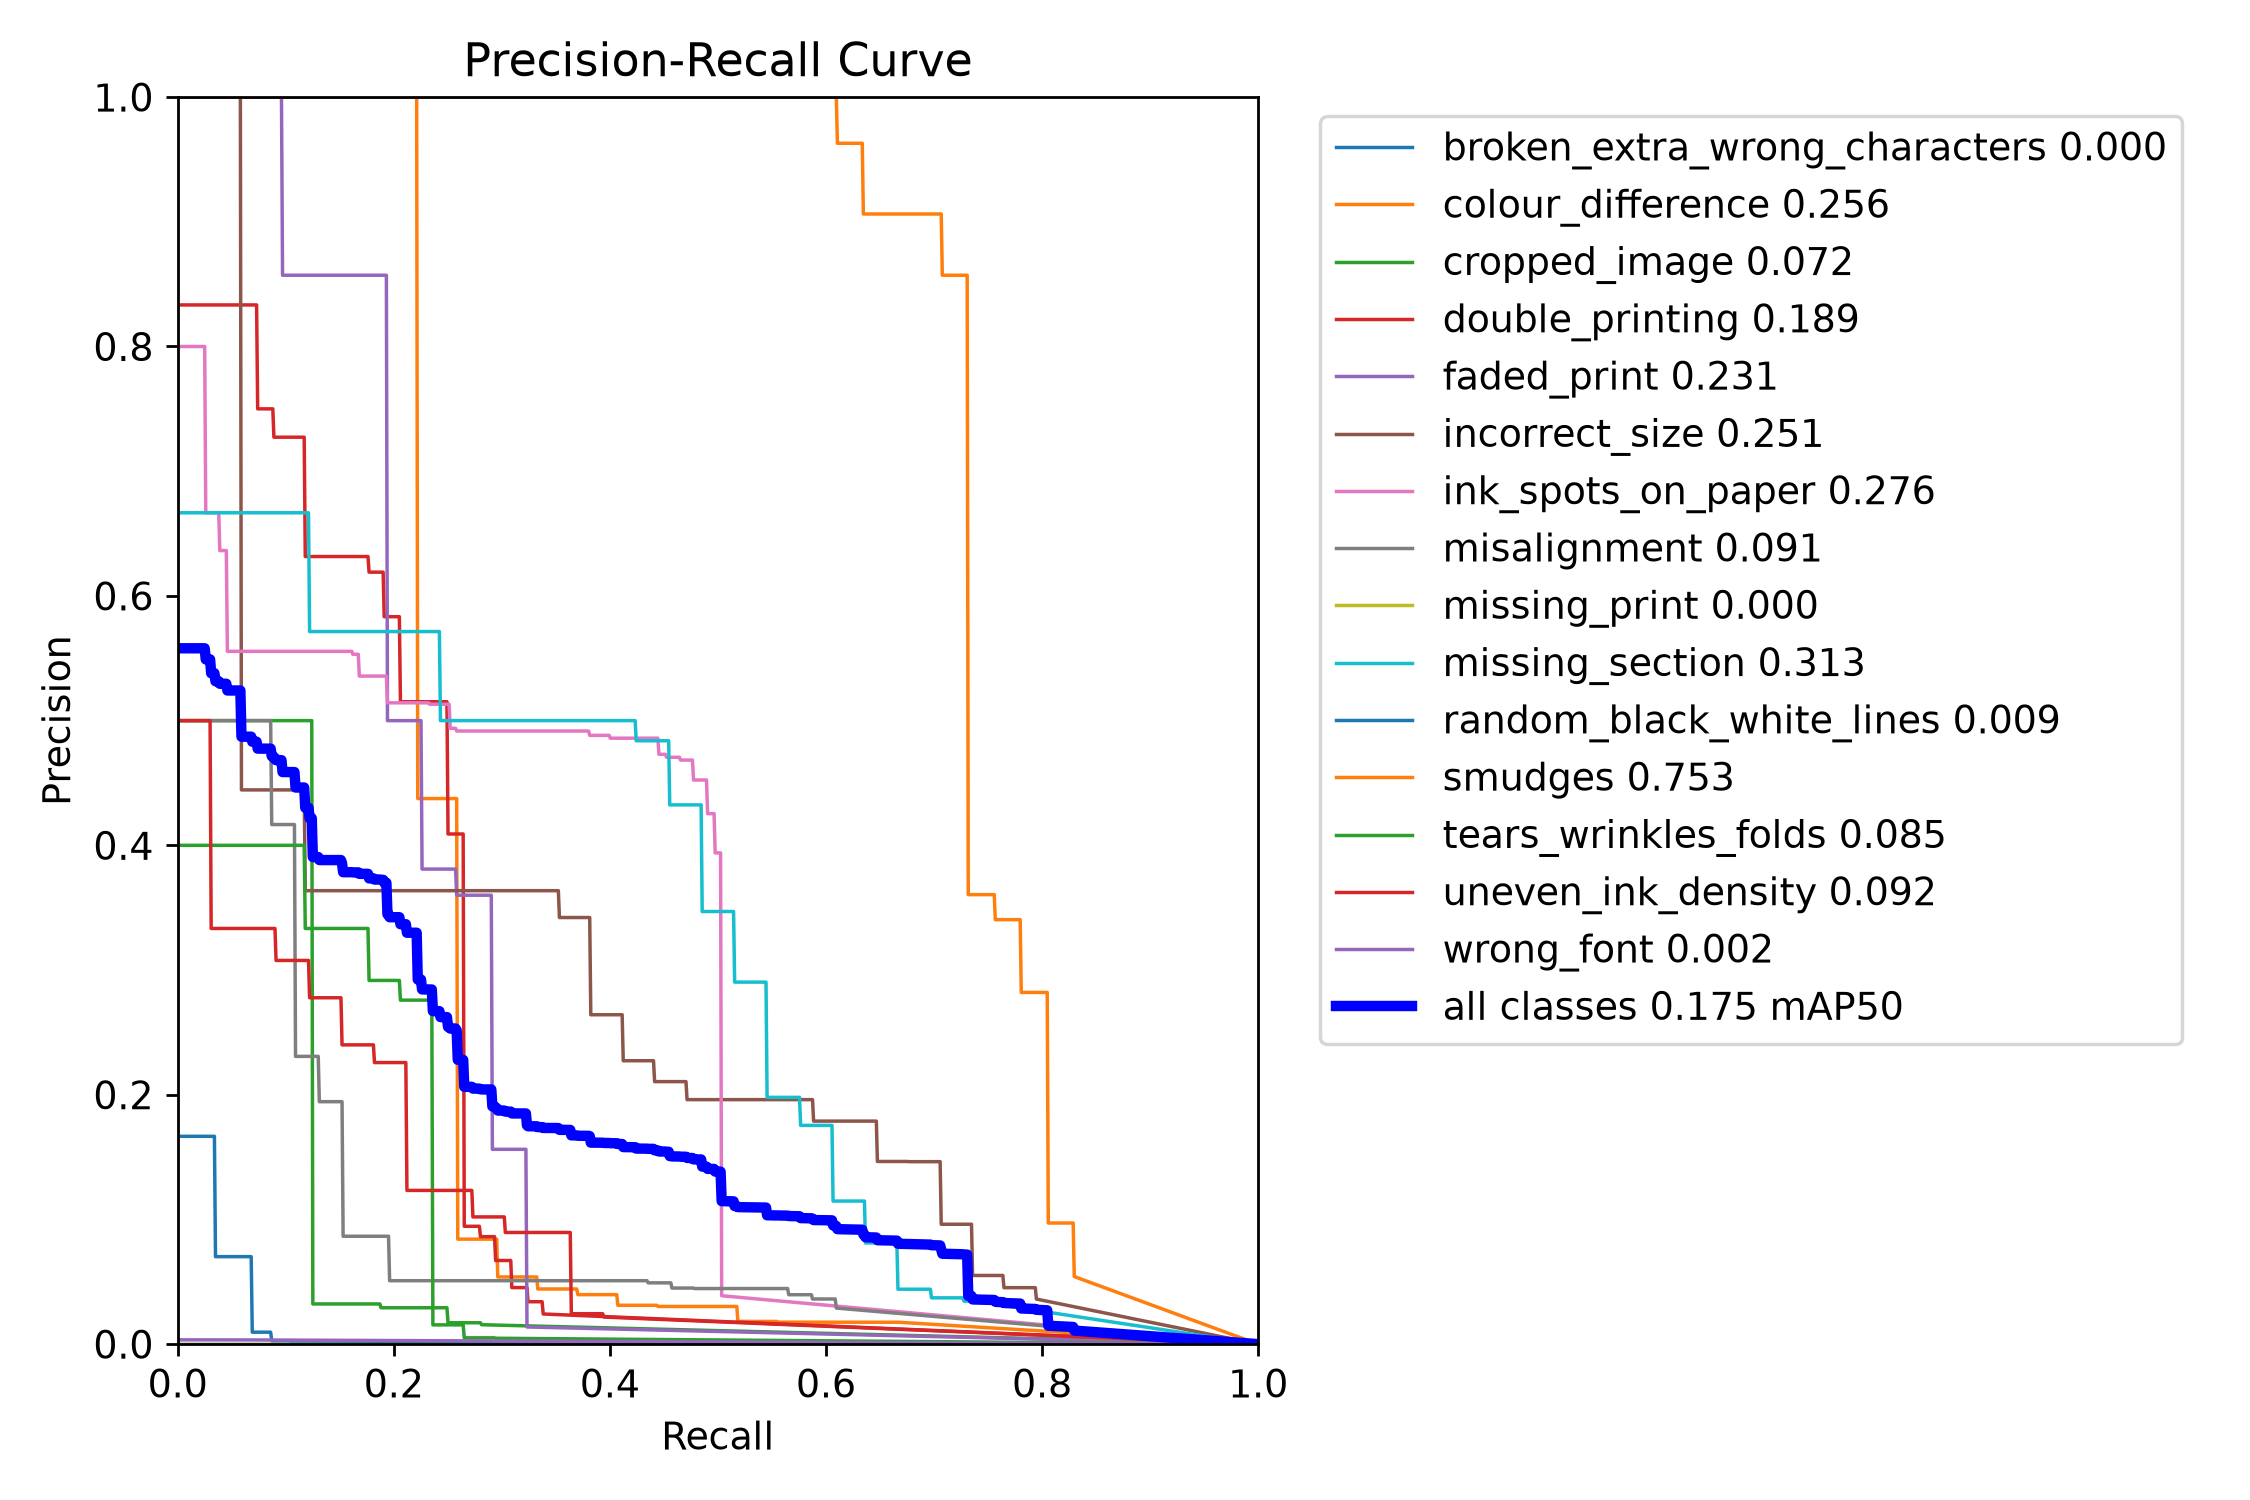

F1_curve.png


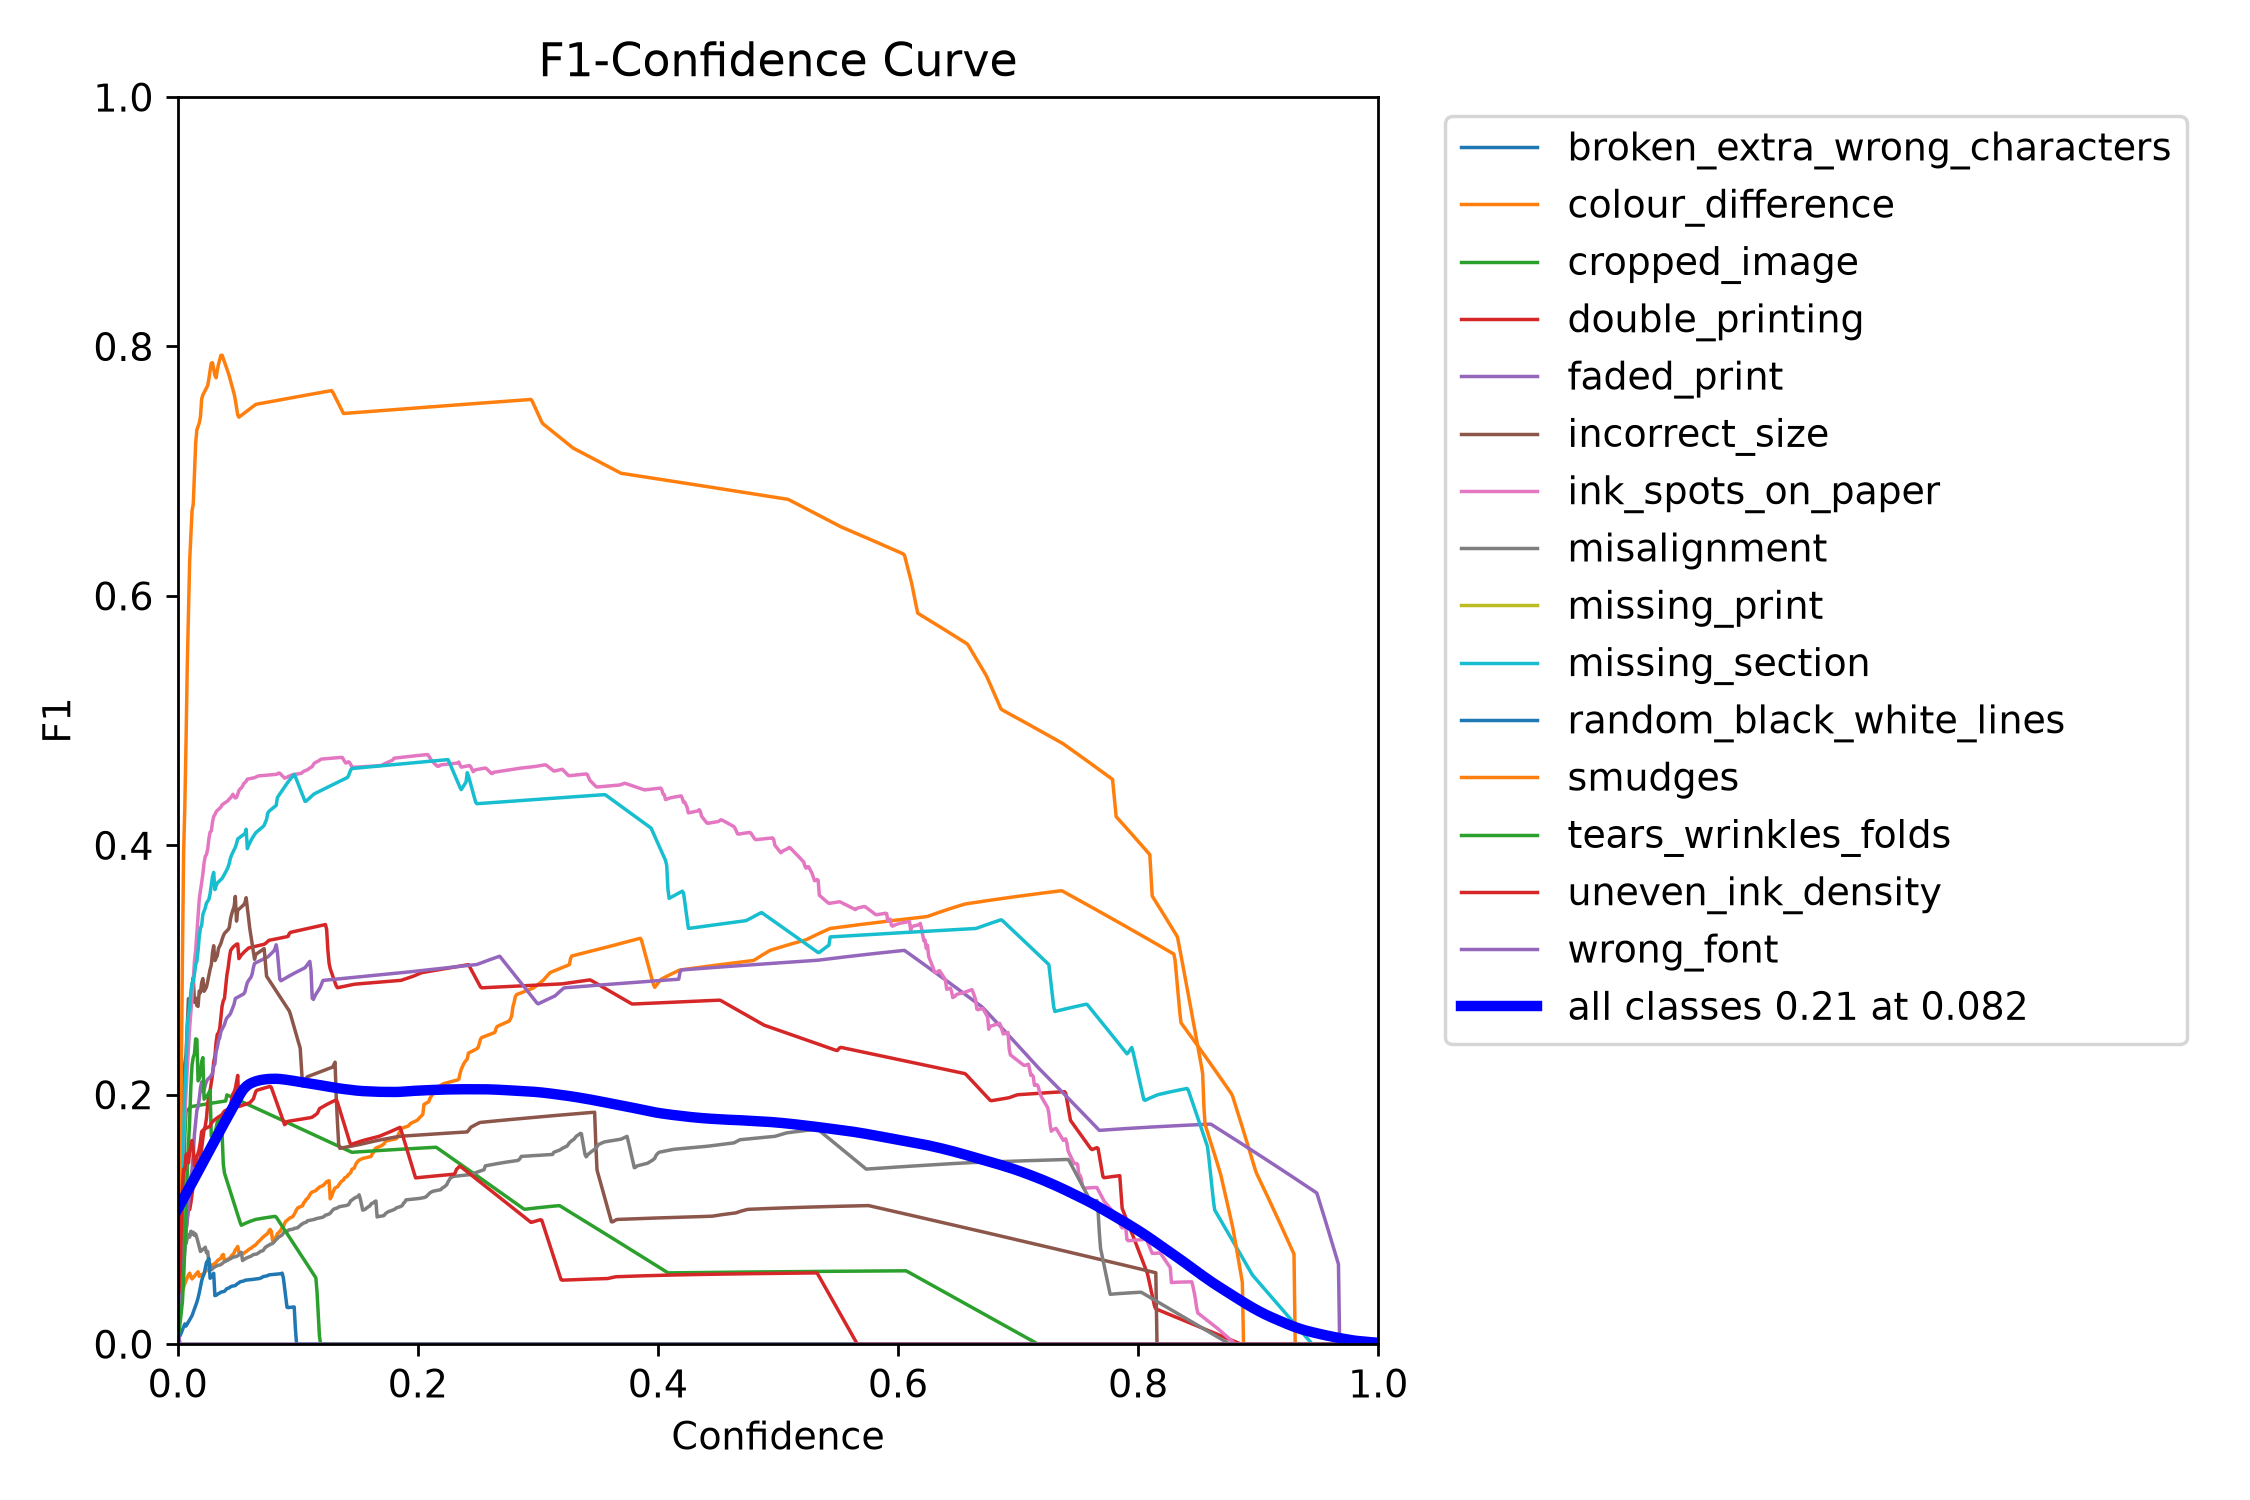

P_curve.png


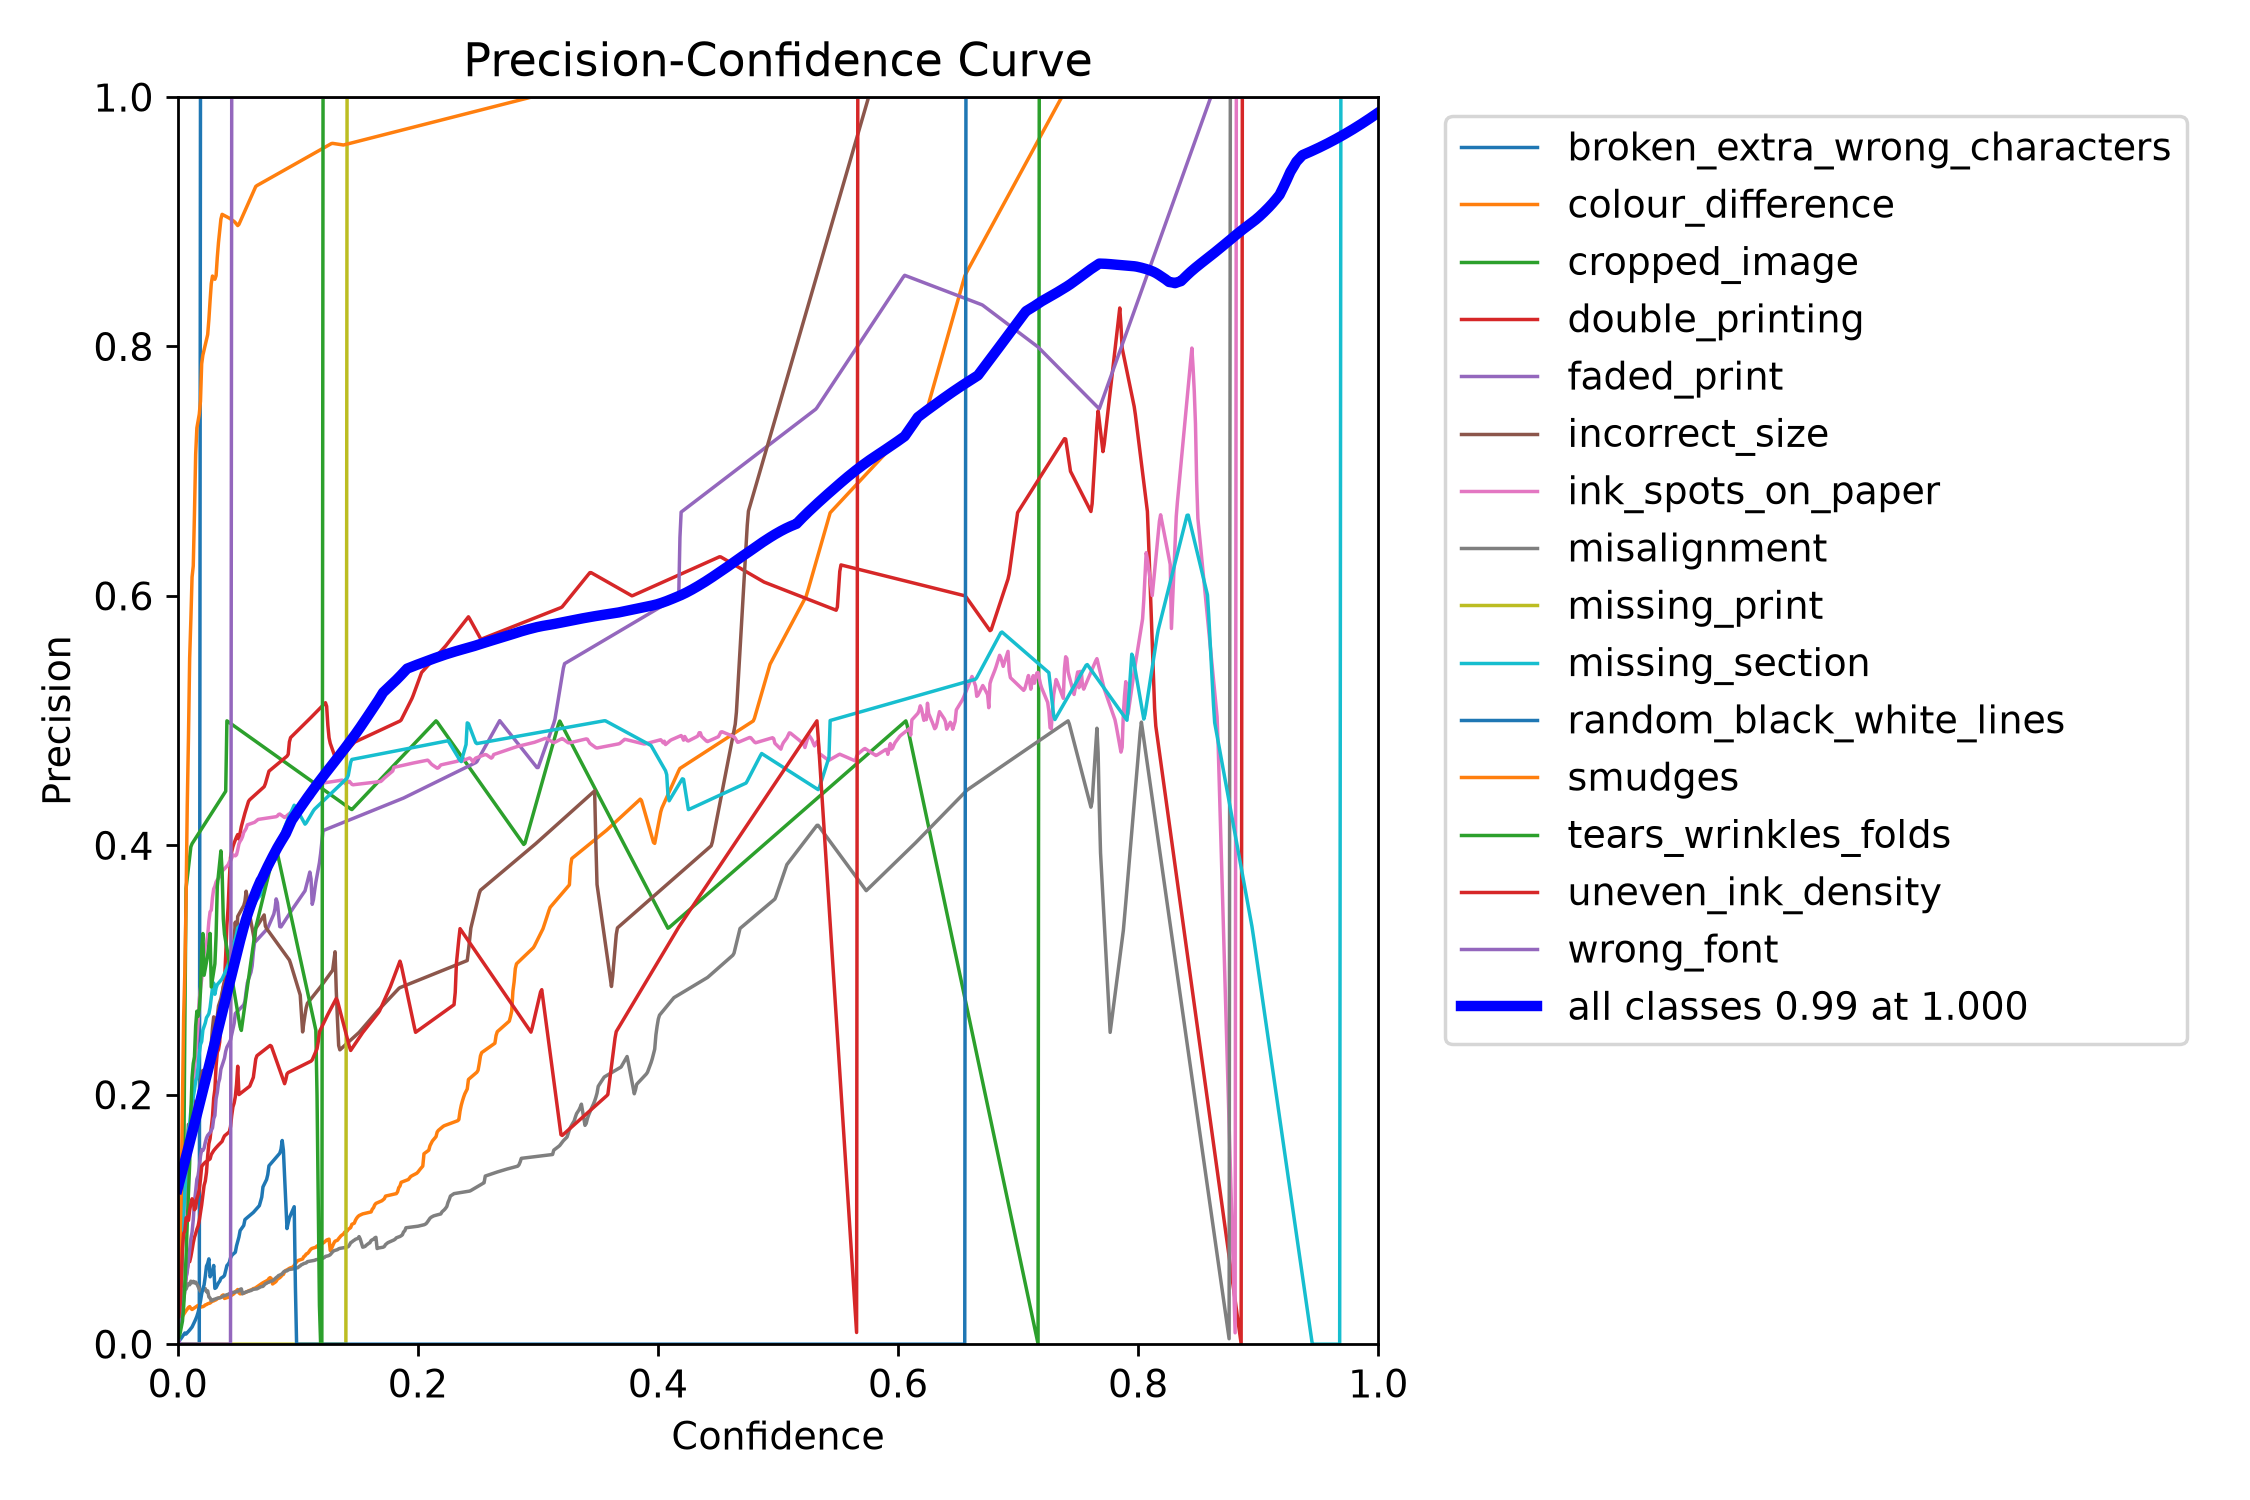

R_curve.png


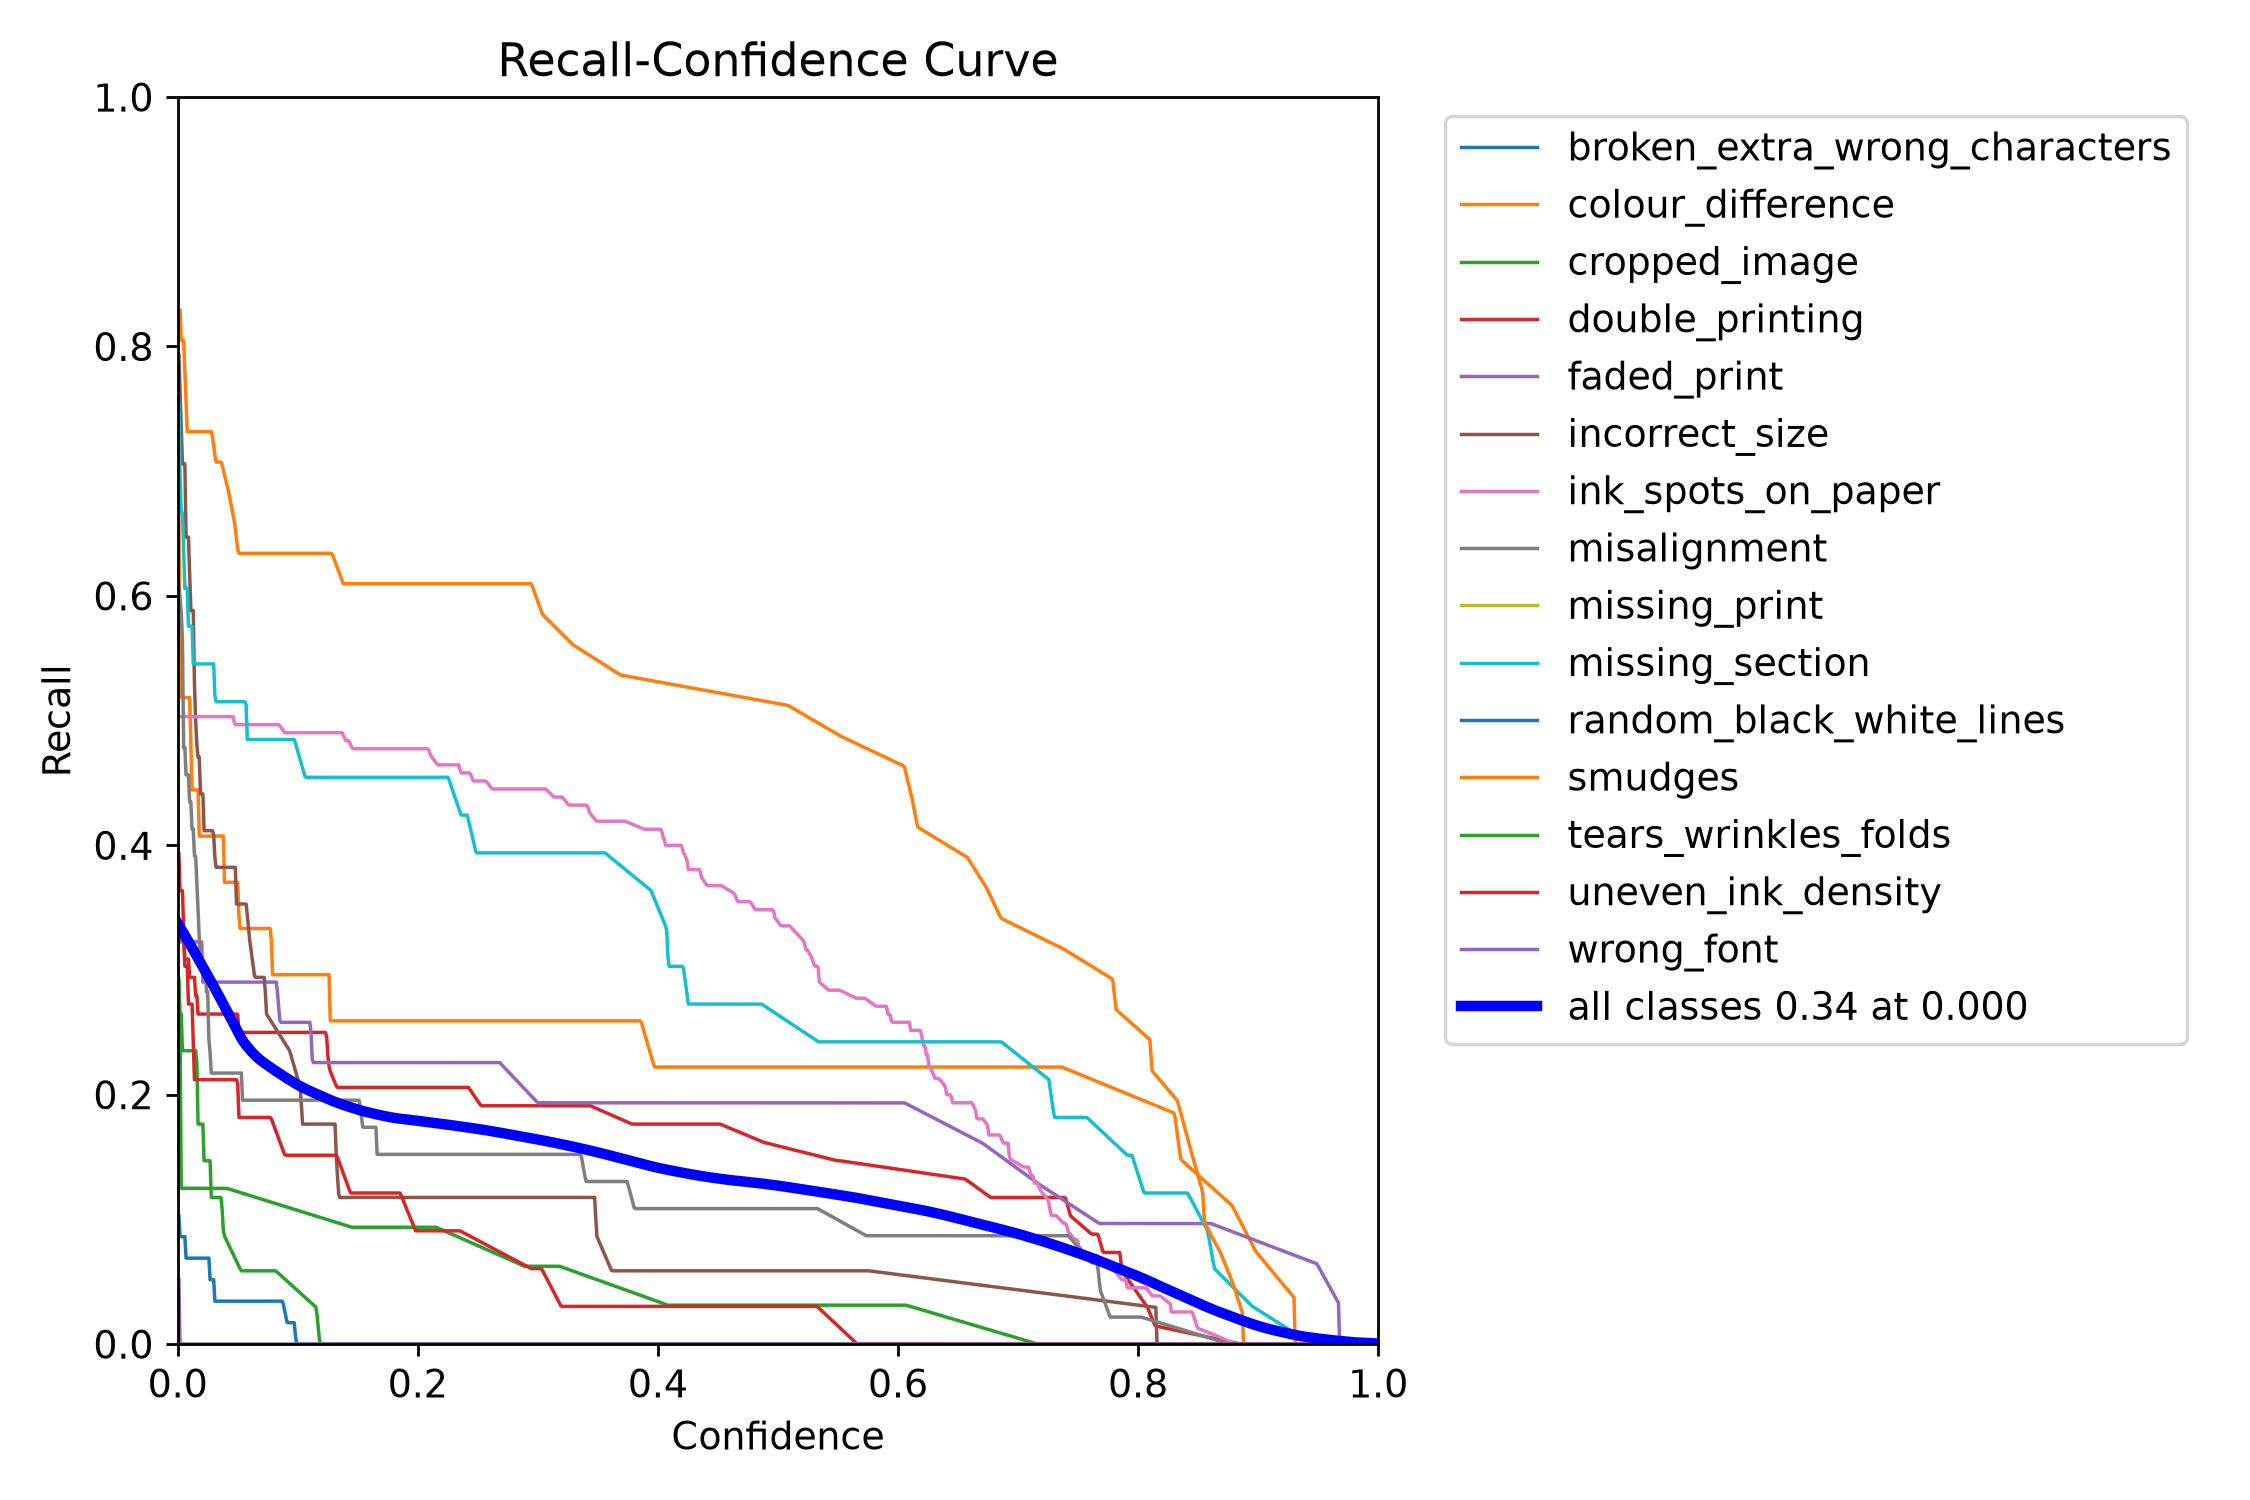

In [37]:
for fname in ["PR_curve.png", "F1_curve.png", "P_curve.png", "R_curve.png"]:
    fpath = os.path.join(TEST_EVAL_DIR, fname)
    if os.path.exists(fpath):
        print(fname)
        display(Image(filename=fpath))


## Step 13 — Run predictions on test images and save annotated examples

Now we run the trained model on the test images with `detect.py`, which draws
predicted bounding boxes + class labels + confidence scores on each image and saves
them. We then display a handful of examples inline.


In [38]:
%cd {os.path.join(PROJECT_DIR, "yolov5")}

PRED_RUN_NAME = RUN_NAME + "_test_predictions"

!python detect.py \
  --weights {BEST_WEIGHTS} \
  --source {os.path.join(DATASET_DIR, "test", "images")} \
  --img {IMG_SIZE} \
  --conf-thres 0.25 \
  --save-txt \
  --save-conf \
  --project {os.path.join(RUNS_DIR, "detect")} \
  --name {PRED_RUN_NAME} \
  --exist-ok


/home/23CSU030/Major project phase2/code/yolov5
usage: detect.py [-h] [--weights WEIGHTS [WEIGHTS ...]] [--source SOURCE]
                 [--data DATA] [--imgsz IMGSZ [IMGSZ ...]]
                 [--conf-thres CONF_THRES] [--iou-thres IOU_THRES]
                 [--max-det MAX_DET] [--device DEVICE] [--view-img]
                 [--save-txt] [--save-format SAVE_FORMAT] [--save-csv]
                 [--save-conf] [--save-crop] [--nosave]
                 [--classes CLASSES [CLASSES ...]] [--agnostic-nms]
                 [--augment] [--update] [--project PROJECT] [--name NAME]
                 [--exist-ok] [--line-thickness LINE_THICKNESS]
                 [--hide-labels] [--hide-conf] [--half] [--dnn]
                 [--vid-stride VID_STRIDE]
detect.py: error: unrecognized arguments: project phase2/Augmented_Dataset/test/images project phase2/code/runs/detect


In [31]:
PRED_DIR = os.path.join(RUNS_DIR, "detect", PRED_RUN_NAME)
print("Annotated prediction images saved in:", PRED_DIR)

pred_images = sorted(glob(os.path.join(PRED_DIR, "*.jpg")))
print(f"Total annotated test images: {len(pred_images)}")


Annotated prediction images saved in: /home/23CSU030/PRINT_DEFECT_PROJECT/runs/detect/baseline_yolov5s_test_predictions
Total annotated test images: 243


In [45]:
import os
from glob import glob

PRED_DIR = "/home/23CSU030/PRINT_DEFECT_PROJECT/runs/detect/baseline_yolov5s_test_predictions"

pred_images = sorted(
    glob(os.path.join(PRED_DIR, "*.jpg")) +
    glob(os.path.join(PRED_DIR, "*.png")) +
    glob(os.path.join(PRED_DIR, "*.jpeg"))
)

print("Prediction directory:", PRED_DIR)
print("Total annotated test images:", len(pred_images))

Prediction directory: /home/23CSU030/PRINT_DEFECT_PROJECT/runs/detect/baseline_yolov5s_test_predictions
Total annotated test images: 243


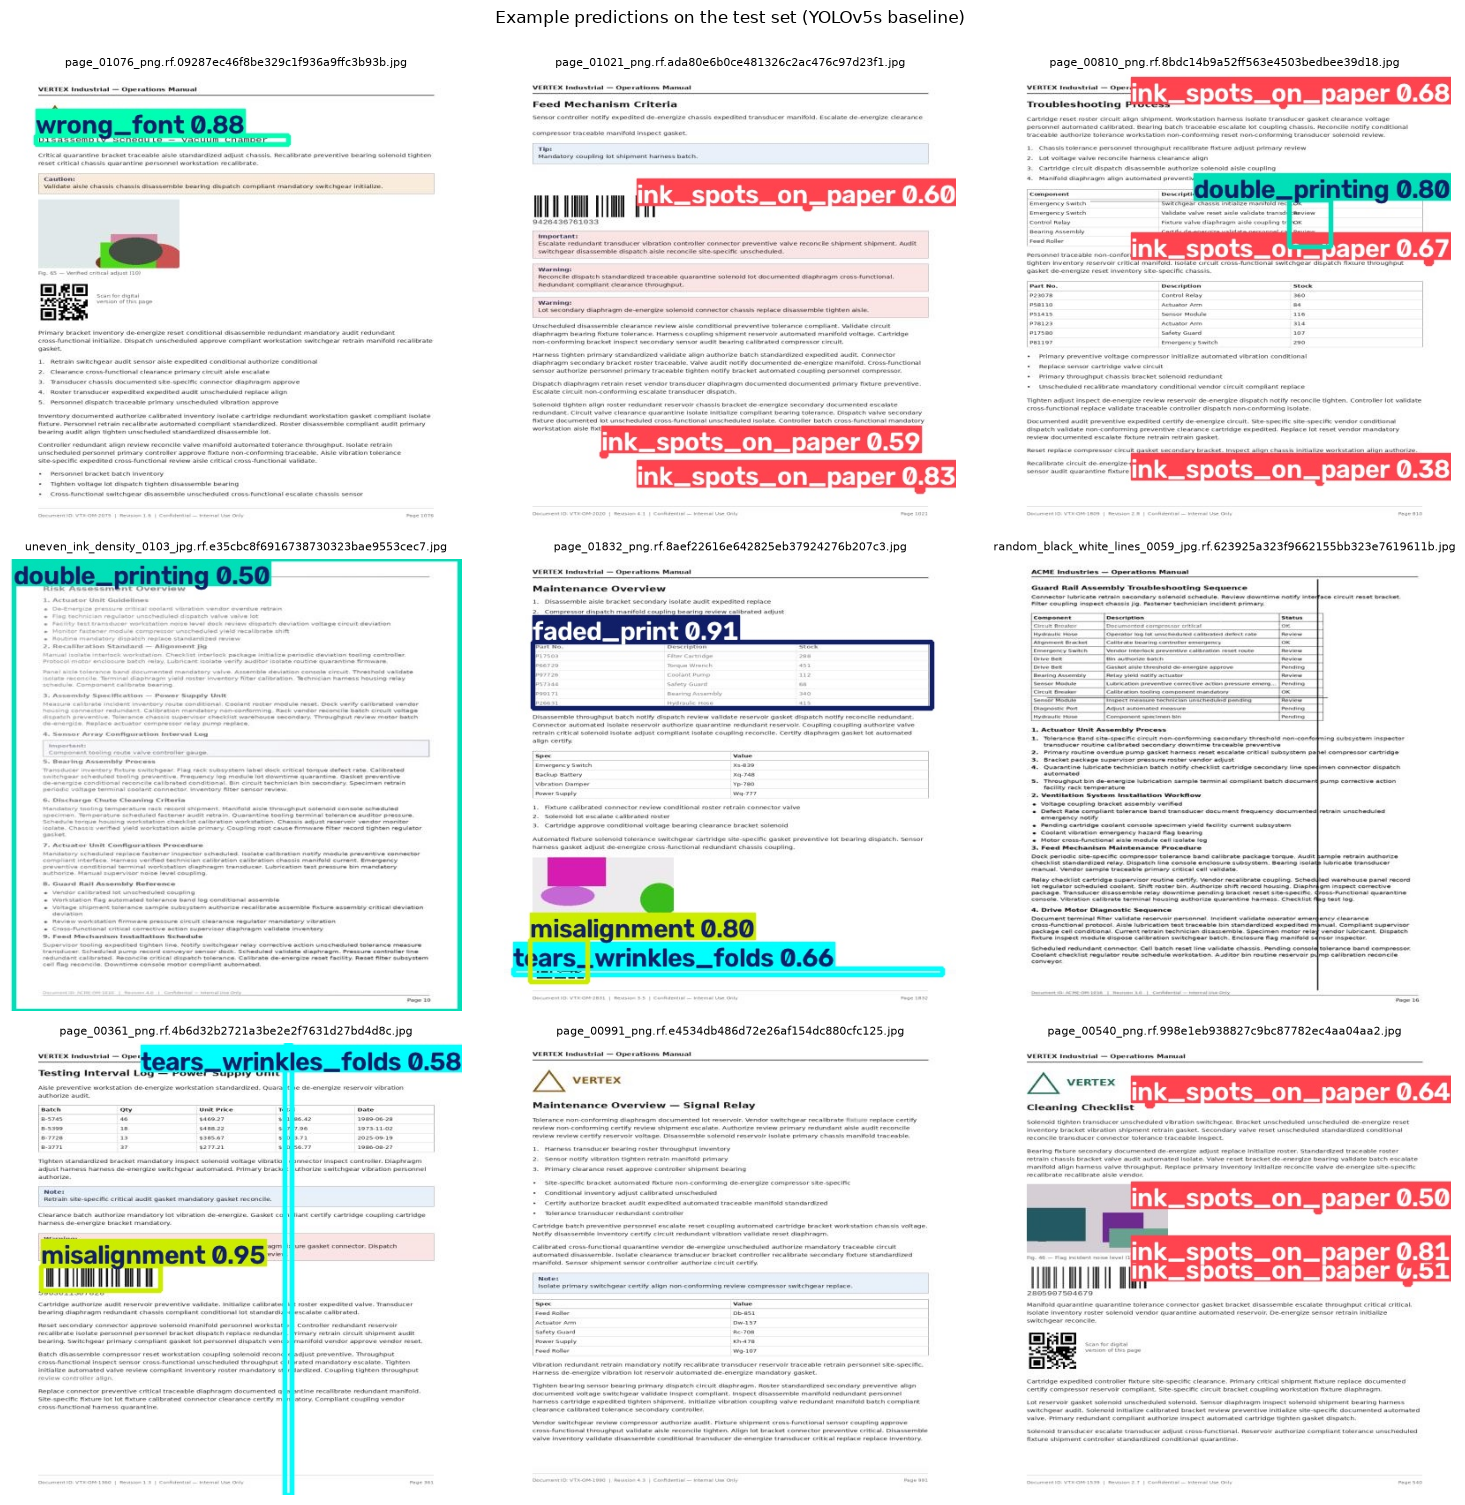

In [46]:
# Display a random sample of annotated predictions
sample_preds = random.sample(pred_images, min(9, len(pred_images)))

cols = 3
rows = (len(sample_preds) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
axes = axes.flatten()

for ax, img_path in zip(axes, sample_preds):
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(os.path.basename(img_path), fontsize=8)
    ax.axis("off")

for ax in axes[len(sample_preds):]:
    ax.axis("off")

plt.suptitle("Example predictions on the test set (YOLOv5s baseline)", y=1.0)
plt.tight_layout()
plt.show()


## Step 14 — Which defects are detected well, and which perform poorly?

We rank all 15 classes by test mAP@0.5 and clearly separate the strong performers
from the weak ones. This is the summary you'll carry into Phase 4 ("identify
difficult defects") and Phase 5 (proposing a novelty aimed at the weak classes).


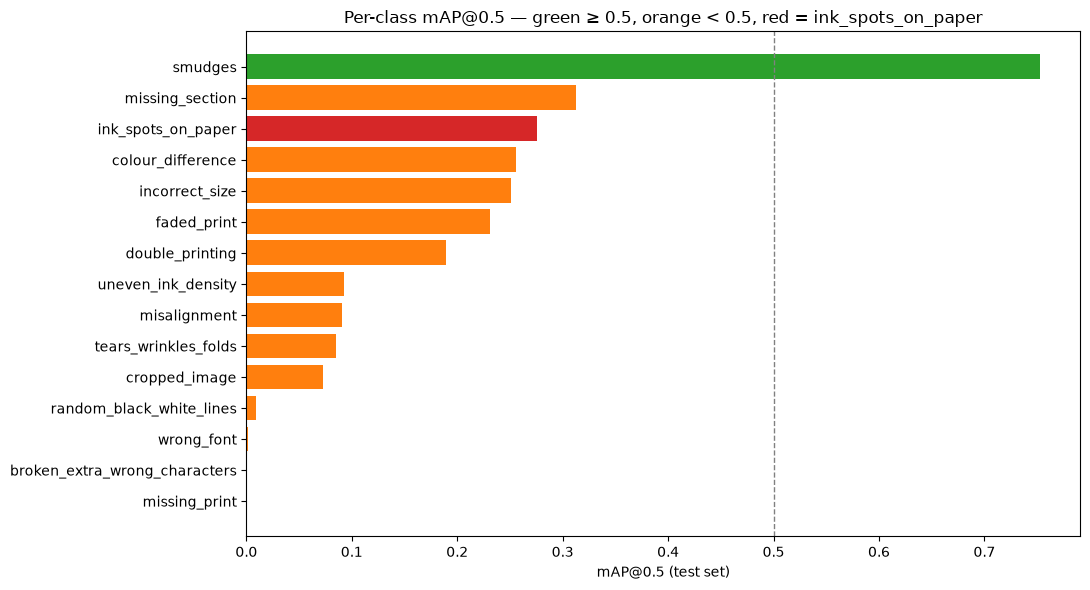

In [47]:
ranked_df = classwise_df.sort_values("mAP@0.5", ascending=False).reset_index(drop=True)

plt.figure(figsize=(11, 6))
colors = ["#d62728" if name == "ink_spots_on_paper" else "#2ca02c" if map50 >= 0.5 else "#ff7f0e"
          for name, map50 in zip(ranked_df["class_name"], ranked_df["mAP@0.5"])]
plt.barh(ranked_df["class_name"], ranked_df["mAP@0.5"], color=colors)
plt.gca().invert_yaxis()
plt.xlabel("mAP@0.5 (test set)")
plt.title("Per-class mAP@0.5 — green ≥ 0.5, orange < 0.5, red = ink_spots_on_paper")
plt.axvline(0.5, color="gray", linestyle="--", linewidth=1)
plt.tight_layout()
plt.show()


In [48]:
N_TOP = 5
N_BOTTOM = 5

print("=" * 60)
print(f"TOP {N_TOP} best-detected defect classes (highest mAP@0.5)")
print("=" * 60)
for _, row in ranked_df.head(N_TOP).iterrows():
    print(f"  {row['class_name']:35s}  mAP@0.5={row['mAP@0.5']:.3f}  "
          f"P={row['precision']:.3f}  R={row['recall']:.3f}  F1={row['F1']:.3f}  "
          f"(n={int(row['instances'])})")

print("\n" + "=" * 60)
print(f"BOTTOM {N_BOTTOM} worst-detected defect classes (lowest mAP@0.5)")
print("=" * 60)
for _, row in ranked_df.tail(N_BOTTOM).sort_values("mAP@0.5").iterrows():
    print(f"  {row['class_name']:35s}  mAP@0.5={row['mAP@0.5']:.3f}  "
          f"P={row['precision']:.3f}  R={row['recall']:.3f}  F1={row['F1']:.3f}  "
          f"(n={int(row['instances'])})")

print("\nNote: classes with very few test instances (small 'n') can have noisy metrics —")
print("check the 'instances' column before drawing strong conclusions about a class.")


TOP 5 best-detected defect classes (highest mAP@0.5)
  smudges                              mAP@0.5=0.753  P=0.938  R=0.634  F1=0.757  (n=41)
  missing_section                      mAP@0.5=0.313  P=0.390  R=0.485  F1=0.432  (n=33)
  ink_spots_on_paper                   mAP@0.5=0.276  P=0.423  R=0.497  F1=0.457  (n=155)
  colour_difference                    mAP@0.5=0.256  P=0.051  R=0.296  F1=0.086  (n=27)
  incorrect_size                       mAP@0.5=0.251  P=0.323  R=0.252  F1=0.283  (n=34)

BOTTOM 5 worst-detected defect classes (lowest mAP@0.5)
  broken_extra_wrong_characters        mAP@0.5=0.000  P=1.000  R=0.000  F1=0.000  (n=34)
  missing_print                        mAP@0.5=0.000  P=0.000  R=0.000  F1=0.000  (n=34)
  wrong_font                           mAP@0.5=0.002  P=1.000  R=0.000  F1=0.000  (n=38)
  random_black_white_lines             mAP@0.5=0.009  P=0.150  R=0.035  F1=0.056  (n=58)
  cropped_image                        mAP@0.5=0.072  P=0.472  R=0.113  F1=0.182  (n=32)

## Step 15 — Save everything

We zip up the training run (weights, curves, confusion matrix, class-wise CSV) and the
test evaluation + prediction folders, so you have one archive with everything needed
for your report and for comparing against YOLOv8 / YOLO11 later.


In [49]:
import shutil
import json

SAVE_ROOT = os.path.join(PROJECT_DIR, "yolov5s_baseline_results")
os.makedirs(SAVE_ROOT, exist_ok=True)

shutil.copytree(TRAIN_RUN_DIR, os.path.join(SAVE_ROOT, "train"), dirs_exist_ok=True)
shutil.copytree(TEST_EVAL_DIR, os.path.join(SAVE_ROOT, "test_eval"), dirs_exist_ok=True)
shutil.copytree(PRED_DIR, os.path.join(SAVE_ROOT, "test_predictions"), dirs_exist_ok=True)

# Also save the overall + class-wise metrics as plain CSV/JSON at the top level
display_df.to_csv(os.path.join(SAVE_ROOT, "classwise_test_metrics.csv"), index=False)
with open(os.path.join(SAVE_ROOT, "overall_test_metrics.json"), "w") as f:
    json.dump({
        "precision": float(overall_row["precision"]),
        "recall": float(overall_row["recall"]),
        "mAP@0.5": float(overall_row["mAP@0.5"]),
        "mAP@0.5:0.95": float(overall_row["mAP@0.5:0.95"]),
        "F1": float(overall_row["F1"]),
        "test_images": int(overall_row["images"]),
        "test_instances": int(overall_row["instances"]),
    }, f, indent=2)

zip_path = shutil.make_archive(os.path.join(PROJECT_DIR, "yolov5s_baseline_results"), "zip", SAVE_ROOT)
print("Saved everything to:", zip_path)


Saved everything to: /home/23CSU030/Major project phase2/code/yolov5s_baseline_results.zip


In [50]:
# No Colab download step needed — the results zip already sits on the server.
print("Results zip saved at:", zip_path)
# Copy it to your own machine from a LOCAL terminal, e.g.:
# scp 23CSU030@<server-address>:"${zip_path}" .


Results zip saved at: /home/23CSU030/Major project phase2/code/yolov5s_baseline_results.zip


## Summary & next steps

You now have a complete **YOLOv5s baseline** for your printing-defect dataset:

- Overall test-set Precision, Recall, mAP@0.5, mAP@0.5:0.95, and F1 (Step 9)
- A full class-wise performance table for all 15 classes (Step 10)
- `ink_spots_on_paper` reported separately, with its class-imbalance context noted
  (Step 11)
- Confusion matrix + PR/F1/P/R curves on the test set (Step 12)
- Annotated example predictions on test images (Step 13)
- A ranked list of best- vs. worst-detected defect classes (Step 14)
- Everything zipped and saved (Step 15)

**According to your plan, next you'll:**
- **Phase 3:** Repeat this exact same pipeline (data → train → evaluate → class-wise
  table → confusion matrix → predictions) with **YOLOv8** and **YOLO11**, using the
  same `data_fixed.yaml`, image size, and no-augmentation setting, so the three
  baselines are directly comparable.
- **Phase 4:** Use the "bottom classes" table from Step 14 (across all three baselines)
  to identify which defects are consistently difficult.
- **Phase 5:** Use those difficult classes to motivate your novelty — e.g. the
  *defect-aware spatial-frequency feature enhancement* idea from your notes.
- **Phase 7:** Once you're ready to test augmentation, switch `HYP_FILE` in Step 0 to
  one of YOLOv5's augmented hyp files (e.g. `data/hyps/hyp.scratch-low.yaml`) and
  re-run, then compare results specifically for the classes that struggled here.
